In [1]:
import json
import hashlib
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from scipy.special import logit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    log_loss
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

RANDOM_STATE = 42

WINDOW_HOURS = 24
ROLLING_STRIDE_HOURS = 6

MIN_WINDOW_ROWS = 1000
MIN_WINDOW_FRAUD = 20

PSI_BINS = 10
PSI_PSEUDOCOUNT = 0.5
PSI_WARNING = 0.10
PSI_CRITICAL = 0.25

MISSING_RATE_WARNING = 0.05

SHAP_SAMPLE_SIZE = 5000
N_JOBS = 2

CALIBRATION_EDGES = np.array([
    0, .001, .005, .01, .025,
    .05, .10, .20, .50, .80, 1.0
])

DATA_PATH = Path("../data/processed")
MODEL_PATH = Path("../models")
RESULTS_PATH = Path("../reports/results")
FIGURES_PATH = Path("../reports/figures")

for path in (RESULTS_PATH, FIGURES_PATH):
    path.mkdir(parents=True, exist_ok=True)

def save_plot(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_PATH / filename,
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

In [2]:
artifact_path = MODEL_PATH / "final_fraud_model.joblib"

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(block)

    return digest.hexdigest()


artifact_hash = sha256_file(artifact_path)

policy_hash = sha256_file(
    MODEL_PATH / "decision_policy.json"
)

artifact = joblib.load(artifact_path)

with open(MODEL_PATH / "decision_policy.json") as f:
    policy = json.load(f)

with open(DATA_PATH / "feature_metadata.json") as f:
    metadata = json.load(f)

with open(
    MODEL_PATH / "final_evaluation_metadata.json"
) as f:
    previous_evaluation = json.load(f)

model = artifact["model"]
calibrator = artifact["calibrator"]

feature_columns = artifact["feature_columns"]
target_column = metadata["target_column"]

EPSILON = artifact["logit_epsilon"]

DECISION_THRESHOLD = float(
    artifact["decision_threshold"]
)

HIGH_RISK_THRESHOLD = float(
    artifact["high_risk_threshold"]
)

MAX_ALERT_RATE = float(
    policy["maximum_policy_alert_rate"]
)

HIGH_RISK_ALERT_RATE = float(
    policy["high_risk_alert_rate"]
)

INVESTIGATION_COST = float(
    policy["investigation_cost"]
)

PREVENTABLE_FRACTION = float(
    policy["preventable_fraud_fraction"]
)

assert (
    feature_columns
    == metadata["feature_columns"]
    == policy["feature_columns"]
)

assert np.isclose(
    DECISION_THRESHOLD,
    policy["decision_threshold"]
)

assert np.isclose(
    HIGH_RISK_THRESHOLD,
    policy["high_risk_threshold"]
)

assert policy["policy_frozen_before_test"]

assert 0 <= DECISION_THRESHOLD <= HIGH_RISK_THRESHOLD
assert 0 < MAX_ALERT_RATE <= 1

print("Model:", policy["model_name"])
print("Investigation threshold:", DECISION_THRESHOLD)
print("High-risk threshold:", HIGH_RISK_THRESHOLD)
print("Capacity target:", f"{MAX_ALERT_RATE:.2%}")

Model: XGBoost - Shallow - 10% Sample
Investigation threshold: 0.16168135726258814
High-risk threshold: 0.9279876292913652
Capacity target: 1.00%


In [3]:
load_columns = feature_columns + [
    target_column,
    "step"
]

val_df = pd.read_parquet(
    DATA_PATH / "validation.parquet",
    columns=load_columns
)

test_df = pd.read_parquet(
    DATA_PATH / "test.parquet",
    columns=load_columns
)

calibration_df = val_df.loc[
    val_df["step"] <= policy["calibration_end_step"]
].copy()

reference_df = val_df.loc[
    val_df["step"] > policy["calibration_end_step"]
].copy()

assert not calibration_df.empty
assert not reference_df.empty
assert not test_df.empty

assert (
    calibration_df["step"].max()
    < reference_df["step"].min()
)

assert (
    reference_df["step"].max()
    < test_df["step"].min()
)

assert (
    reference_df["step"].min()
    == policy["policy_start_step"]
)

assert (
    reference_df["step"].max()
    == policy["policy_end_step"]
)

assert (
    test_df["step"].min()
    > metadata["validation_end_step"]
)

del val_df


def score_transactions(df):

    df = (
        df.sort_values("step", kind="stable")
        .reset_index(drop=True)
        .copy()
    )

    raw = np.asarray(
        model.predict_proba(
            df[feature_columns]
        )[:, 1],
        dtype=np.float64
    )

    clipped = np.clip(
        raw,
        EPSILON,
        1 - EPSILON
    )

    z = np.log(
        clipped / (1 - clipped)
    ).reshape(-1, 1)

    calibrated = calibrator.predict_proba(z)[:, 1]

    assert np.isfinite(calibrated).all()

    assert (
        (calibrated >= 0)
        & (calibrated <= 1)
    ).all()

    df["raw_probability"] = raw

    df["fraud_probability"] = calibrated

    df["prediction"] = (
        calibrated >= DECISION_THRESHOLD
    ).astype(np.int8)

    df["risk_tier"] = np.select(
        [
            calibrated >= HIGH_RISK_THRESHOLD,
            calibrated >= DECISION_THRESHOLD
        ],
        [
            "High Risk",
            "Medium Risk"
        ],
        default="Low Risk"
    )

    assert df[target_column].isin([0, 1]).all()

    return df


calibration_df = score_transactions(calibration_df)

reference_df = score_transactions(reference_df)

test_df = score_transactions(test_df)

periods = {
    "Calibration": calibration_df,
    "Policy reference": reference_df,
    "Test": test_df
}

pd.DataFrame([
    {
        "period": name,
        "start_step": df.step.min(),
        "end_step": df.step.max(),
        "transactions": len(df),
        "fraud_count": int(df[target_column].sum()),
        "fraud_rate": df[target_column].mean()
    }
    for name, df in periods.items()
])

,period,start_step,end_step,transactions,fraud_count,fraud_rate
0,Calibration,446,519,68033,762,0.011200
1,Policy reference,520,594,160070,790,0.004935
2,Test,595,743,123580,1654,0.013384


In [4]:
def safe_divide(a, b):
    return float(a / b) if b else np.nan


def calibration_bins(y, p):

    y = np.asarray(y)
    p = np.asarray(p, dtype=float)

    bin_ids = np.searchsorted(
        CALIBRATION_EDGES[1:-1],
        p,
        side="right"
    )

    rows = []

    for i in range(len(CALIBRATION_EDGES) - 1):

        mask = bin_ids == i

        rows.append({
            "bin": i,
            "lower": CALIBRATION_EDGES[i],
            "upper": CALIBRATION_EDGES[i + 1],
            "count": int(mask.sum()),
            "mean_probability": (
                p[mask].mean() if mask.any() else np.nan
            ),
            "observed_fraud_rate": (
                y[mask].mean() if mask.any() else np.nan
            )
        })

    return pd.DataFrame(rows)


def expected_calibration_error(y, p):

    bins = calibration_bins(y, p).dropna(
        subset=["mean_probability"]
    )

    return safe_divide(
        (
            bins["count"]
            * (
                bins["mean_probability"]
                - bins["observed_fraud_rate"]
            ).abs()
        ).sum(),
        len(y)
    )


def evaluate_window(df, decisions=None):

    y = df[target_column].to_numpy(dtype=int)

    p = df["fraud_probability"].to_numpy(dtype=float)

    raw = df["raw_probability"].to_numpy(dtype=float)

    amount = df["amount"].to_numpy(dtype=float)

    pred = (
        df["prediction"].to_numpy(dtype=bool)
        if decisions is None
        else np.asarray(decisions, dtype=bool)
    )

    assert len(pred) == len(df)

    fraud = y == 1

    tp = int((pred & fraud).sum())
    fp = int((pred & ~fraud).sum())
    fn = int((~pred & fraud).sum())
    tn = int((~pred & ~fraud).sum())

    alerts = tp + fp
    total_fraud = tp + fn

    total_value = amount[fraud].sum()
    detected_value = amount[fraud & pred].sum()
    missed_value = amount[fraud & ~pred].sum()

    cost = (
        INVESTIGATION_COST * alerts
        + PREVENTABLE_FRACTION * missed_value
    )

    both_classes = len(np.unique(y)) == 2

    capacity = int(
        np.floor(MAX_ALERT_RATE * len(df) + 1e-9)
    )

    return {
        "transactions": len(df),

        "fraud_count": total_fraud,

        "fraud_rate": safe_divide(
            total_fraud, len(df)
        ),

        "mean_probability": (
            p.mean() if len(p) else np.nan
        ),

        "mean_raw_probability": (
            raw.mean() if len(p) else np.nan
        ),

        "calibration_gap": (
            p.mean() - y.mean() if len(p) else np.nan
        ),

        "average_precision": (
            average_precision_score(y, p)
            if both_classes else np.nan
        ),

        "roc_auc": (
            roc_auc_score(y, p)
            if both_classes else np.nan
        ),

        "precision": safe_divide(tp, alerts),

        "recall": safe_divide(tp, total_fraud),

        "f1": safe_divide(
            2 * tp, 2 * tp + fp + fn
        ),

        "brier_score": (
            brier_score_loss(y, p)
            if len(y) else np.nan
        ),

        "raw_brier_score": (
            brier_score_loss(y, raw)
            if len(y) else np.nan
        ),

        "log_loss": (
            log_loss(y, p, labels=[0, 1])
            if len(y) else np.nan
        ),

        "raw_log_loss": (
            log_loss(y, raw, labels=[0, 1])
            if len(y) else np.nan
        ),

        "ece": (
            expected_calibration_error(y, p)
            if len(y) else np.nan
        ),

        "alert_count": alerts,

        "alert_rate": safe_divide(
            alerts, len(df)
        ),

        "high_risk_rate": safe_divide(
            (p >= HIGH_RISK_THRESHOLD).sum(),
            len(df)
        ),

        "capacity_exceeded": bool(
            alerts > capacity
        ),

        "excess_alerts": max(
            0, alerts - capacity
        ),

        "true_positives": tp,
        "false_positives": fp,
        "true_negatives": tn,
        "false_negatives": fn,

        "total_fraud_amount": total_value,
        "detected_fraud_amount": detected_value,
        "missed_fraud_amount": missed_value,

        "fraud_value_captured": safe_divide(
            detected_value, total_value
        ),

        "hypothetical_total_cost": cost,

        "hypothetical_savings": (
            PREVENTABLE_FRACTION * total_value - cost
        ),

        "hypothetical_cost_per_1000": safe_divide(
            1000 * cost, len(df)
        ),

        "low_support": bool(
            len(df) < MIN_WINDOW_ROWS
            or total_fraud < MIN_WINDOW_FRAUD
        )
    }


period_results = pd.DataFrame([
    {
        "period": name,
        **evaluate_window(df)
    }
    for name, df in periods.items()
])

period_results.round(6)

,period,transactions,fraud_count,fraud_rate,mean_probability,mean_raw_probability,calibration_gap,average_precision,roc_auc,precision,recall,f1,brier_score,raw_brier_score,log_loss,raw_log_loss,ece,alert_count,alert_rate,high_risk_rate,capacity_exceeded,excess_alerts,true_positives,false_positives,true_negatives,false_negatives,total_fraud_amount,detected_fraud_amount,missed_fraud_amount,fraud_value_captured,hypothetical_total_cost,hypothetical_savings,hypothetical_cost_per_1000,low_support
0,Calibration,68033,762,0.011200,0.011205,0.003157,0.000005,0.648429,0.967737,0.442462,0.650919,0.526819,0.005948,0.008052,0.024822,0.036143,0.001935,1121,0.016477,0.002411,True,441,496,625,66646,266,1.100116e+09,1.024216e+09,7.589987e+07,0.931007,7.702087e+06,1.023095e+08,113211.049006,False
1,Policy reference,160070,790,0.004935,0.007388,0.001676,0.002453,0.577365,0.968702,0.322459,0.650633,0.431208,0.003012,0.003619,0.013966,0.016727,0.002453,1594,0.009958,0.001000,False,0,514,1080,158200,276,9.325648e+08,8.671688e+08,6.539604e+07,0.929875,6.699004e+06,8.655748e+07,41850.463766,False
2,Test,123580,1654,0.013384,0.011793,0.003588,-0.001591,0.674554,0.966435,0.550346,0.624547,0.585103,0.006807,0.009549,0.028704,0.043910,0.001969,1877,0.015189,0.002954,True,642,1033,844,121082,621,2.722435e+09,2.558666e+09,1.637681e+08,0.939845,1.656451e+07,2.556789e+08,134038.781105,False


In [5]:
actual = period_results.set_index(
    "period"
).loc["Test"]

assert (
    int(actual["transactions"])
    == previous_evaluation["test_transactions"]
)

assert (
    int(actual["fraud_count"])
    == previous_evaluation["test_fraudulent_transactions"]
)

for key in [
    "average_precision",
    "roc_auc",
    "precision",
    "recall",
    "f1",
    "alert_rate",
    "fraud_value_captured"
]:

    np.testing.assert_allclose(
        actual[key],
        previous_evaluation[f"test_{key}"],
        atol=1e-6,
        rtol=1e-6
    )

print("Frozen test performance reproduced successfully.")

Frozen test performance reproduced successfully.


In [6]:
TEST_START = int(test_df.step.min())
TEST_END = int(test_df.step.max())


def iter_fixed_windows(
    df,
    start,
    end,
    hours=WINDOW_HOURS
):

    for lo in range(start, end + 1, hours):

        hi = min(lo + hours - 1, end)

        subset = df.loc[
            df.step.between(lo, hi)
        ]

        yield lo, hi, subset


fixed_windows = list(
    iter_fixed_windows(
        test_df,
        TEST_START,
        TEST_END
    )
)

window_results = pd.DataFrame([
    {
        "start_step": lo,
        "end_step": hi,
        "window_hours": hi - lo + 1,
        "partial_window": (
            hi - lo + 1 < WINDOW_HOURS
        ),
        **evaluate_window(df)
    }
    for lo, hi, df in fixed_windows
])

assert window_results.transactions.sum() == len(test_df)

assert (
    window_results.fraud_count.sum()
    == test_df[target_column].sum()
)

assert (
    window_results.alert_count.sum()
    == test_df.prediction.sum()
)

window_results.round(6)

,start_step,end_step,window_hours,partial_window,transactions,fraud_count,fraud_rate,mean_probability,mean_raw_probability,calibration_gap,average_precision,roc_auc,precision,recall,f1,brier_score,raw_brier_score,log_loss,raw_log_loss,ece,alert_count,alert_rate,high_risk_rate,capacity_exceeded,excess_alerts,true_positives,false_positives,true_negatives,false_negatives,total_fraud_amount,detected_fraud_amount,missed_fraud_amount,fraud_value_captured,hypothetical_total_cost,hypothetical_savings,hypothetical_cost_per_1000,low_support
0,595,618,24,False,29943,266,0.008884,0.009575,0.002558,0.000692,0.619779,0.966888,0.430446,0.616541,0.506955,0.004958,0.006463,0.021402,0.029931,0.001624,381,0.012724,0.001870,True,82,164,217,29460,102,3.677568e+08,3.365191e+08,31237768.43,0.915059,3161876.843,3.361381e+07,1.055965e+05,False
1,619,642,24,False,10192,262,0.025706,0.015078,0.005614,-0.010628,0.734952,0.967414,0.779570,0.553435,0.647321,0.013091,0.018878,0.053194,0.089590,0.010891,186,0.018250,0.005200,True,85,145,41,9889,117,3.360592e+08,3.039886e+08,32070674.83,0.904568,3225667.483,3.038026e+07,3.164901e+05,False
2,643,666,24,False,13189,266,0.020168,0.016396,0.005076,-0.003773,0.684072,0.960999,0.640000,0.601504,0.620155,0.010328,0.014511,0.042602,0.066862,0.006239,250,0.018955,0.004019,True,119,160,90,12833,106,4.179422e+08,3.893981e+08,28544083.50,0.931703,2879408.350,3.891481e+07,2.183189e+05,False
3,667,690,24,False,41489,244,0.005881,0.008081,0.002223,0.002200,0.657716,0.973086,0.402010,0.655738,0.498442,0.003103,0.003888,0.014464,0.018021,0.002390,398,0.009593,0.001591,False,0,160,238,41007,84,5.280006e+08,5.054338e+08,22566820.64,0.957260,2296482.064,5.050358e+07,5.535159e+04,False
4,691,714,24,False,24902,274,0.011003,0.011589,0.003302,0.000586,0.670653,0.966347,0.463592,0.697080,0.556851,0.005548,0.007676,0.023824,0.034411,0.001885,412,0.016545,0.002851,True,163,191,221,24407,83,4.966998e+08,4.770558e+08,19644038.15,0.960451,2005603.815,4.766438e+07,8.053987e+04,False
5,715,738,24,False,3805,282,0.074113,0.039417,0.014935,-0.034696,0.828364,0.966146,0.823810,0.613475,0.703252,0.034146,0.054077,0.132901,0.244600,0.034965,210,0.055191,0.014717,True,172,173,37,3486,109,4.320826e+08,4.055468e+08,26535805.93,0.938586,2674580.593,4.053368e+07,7.029121e+05,False
6,739,743,5,True,60,60,1.000000,0.447918,0.188030,-0.552082,NaN,NaN,1.000000,0.666667,0.800000,0.439255,0.743377,1.723407,3.331792,0.552082,40,0.666667,0.166667,True,40,40,0,0,20,1.438933e+08,1.407244e+08,3168934.21,0.977977,320893.421,1.406844e+07,5.348224e+06,True


In [7]:
rolling_ends = list(
    range(
        TEST_START + WINDOW_HOURS - 1,
        TEST_END + 1,
        ROLLING_STRIDE_HOURS
    )
)

if (
    TEST_END >= TEST_START + WINDOW_HOURS - 1
    and TEST_END not in rolling_ends
):
    rolling_ends.append(TEST_END)

rolling_results = pd.DataFrame([
    {
        "start_step": hi - WINDOW_HOURS + 1,
        "end_step": hi,

        **evaluate_window(
            test_df.loc[
                test_df.step.between(
                    hi - WINDOW_HOURS + 1,
                    hi
                )
            ]
        )
    }
    for hi in rolling_ends
])

rolling_results.round(6)

,start_step,end_step,transactions,fraud_count,fraud_rate,mean_probability,mean_raw_probability,calibration_gap,average_precision,roc_auc,precision,recall,f1,brier_score,raw_brier_score,log_loss,raw_log_loss,ece,alert_count,alert_rate,high_risk_rate,capacity_exceeded,excess_alerts,true_positives,false_positives,true_negatives,false_negatives,total_fraud_amount,detected_fraud_amount,missed_fraud_amount,fraud_value_captured,hypothetical_total_cost,hypothetical_savings,hypothetical_cost_per_1000,low_support
0,595,618,29943,266,0.008884,0.009575,0.002558,0.000692,0.619779,0.966888,0.430446,0.616541,0.506955,0.004958,0.006463,0.021402,0.029931,0.001624,381,0.012724,0.001870,True,82,164,217,29460,102,3.677568e+08,3.365191e+08,31237768.43,0.915059,3161876.843,3.361381e+07,1.055965e+05,False
1,601,624,13885,272,0.019589,0.013710,0.004599,-0.005880,0.738012,0.971444,0.808612,0.621324,0.702703,0.009726,0.014262,0.039139,0.065221,0.006197,209,0.015052,0.004105,True,71,169,40,13573,103,3.959370e+08,3.650489e+08,30888105.78,0.921987,3109710.578,3.648399e+07,2.239619e+05,False
2,607,630,13172,268,0.020346,0.013788,0.004579,-0.006558,0.737072,0.971109,0.775229,0.630597,0.695473,0.010117,0.014984,0.040528,0.068192,0.006806,218,0.016550,0.003948,True,87,169,49,12855,99,4.135452e+08,3.833369e+08,30208260.54,0.926953,3042626.054,3.831189e+07,2.309920e+05,False
3,613,636,8250,264,0.032000,0.018660,0.007307,-0.013340,0.805198,0.974353,0.829146,0.625000,0.712743,0.014901,0.022784,0.058124,0.103632,0.013596,199,0.024121,0.007273,True,117,165,34,7952,99,4.394173e+08,4.062356e+08,33181747.87,0.924487,3338074.787,4.060366e+07,4.046151e+05,False
4,619,642,10192,262,0.025706,0.015078,0.005614,-0.010628,0.734952,0.967414,0.779570,0.553435,0.647321,0.013091,0.018878,0.053194,0.089590,0.010891,186,0.018250,0.005200,True,85,145,41,9889,117,3.360592e+08,3.039886e+08,32070674.83,0.904568,3225667.483,3.038026e+07,3.164901e+05,False
5,625,648,8578,280,0.032642,0.019179,0.007369,-0.013462,0.744171,0.960671,0.741784,0.564286,0.640974,0.016036,0.023598,0.065107,0.111002,0.013729,213,0.024831,0.006761,True,128,158,55,8243,122,4.375958e+08,4.071411e+08,30454710.18,0.930404,3066771.018,4.069281e+07,3.575159e+05,False
6,631,654,8687,282,0.032462,0.018677,0.007181,-0.013786,0.762329,0.962581,0.809278,0.556738,0.659664,0.015595,0.023392,0.063705,0.110121,0.014069,194,0.022332,0.006562,True,108,157,37,8368,125,4.079375e+08,3.771347e+08,30802807.94,0.924491,3099680.794,3.769407e+07,3.568183e+05,False
7,637,660,13126,282,0.021484,0.016337,0.005056,-0.005147,0.675329,0.955954,0.658537,0.574468,0.613636,0.011320,0.015798,0.047245,0.074279,0.007980,246,0.018741,0.003885,True,115,162,84,12760,120,3.956494e+08,3.702700e+08,25379415.43,0.935854,2562541.543,3.700240e+07,1.952264e+05,False
8,643,666,13189,266,0.020168,0.016396,0.005076,-0.003773,0.684072,0.960999,0.640000,0.601504,0.620155,0.010328,0.014511,0.042602,0.066862,0.006239,250,0.018955,0.004019,True,119,160,90,12833,106,4.179422e+08,3.893981e+08,28544083.50,0.931703,2879408.350,3.891481e+07,2.183189e+05,False
9,649,672,14661,248,0.016916,0.015191,0.004547,-0.001725,0.661576,0.964723,0.601626,0.596774,0.599190,0.008968,0.012047,0.037135,0.055794,0.005077,246,0.016779,0.003547,True,100,148,98,14315,100,3.778720e+08,3.502780e+08,27594076.26,0.926975,2784007.626,3.500320e+07,1.898921e+05,False


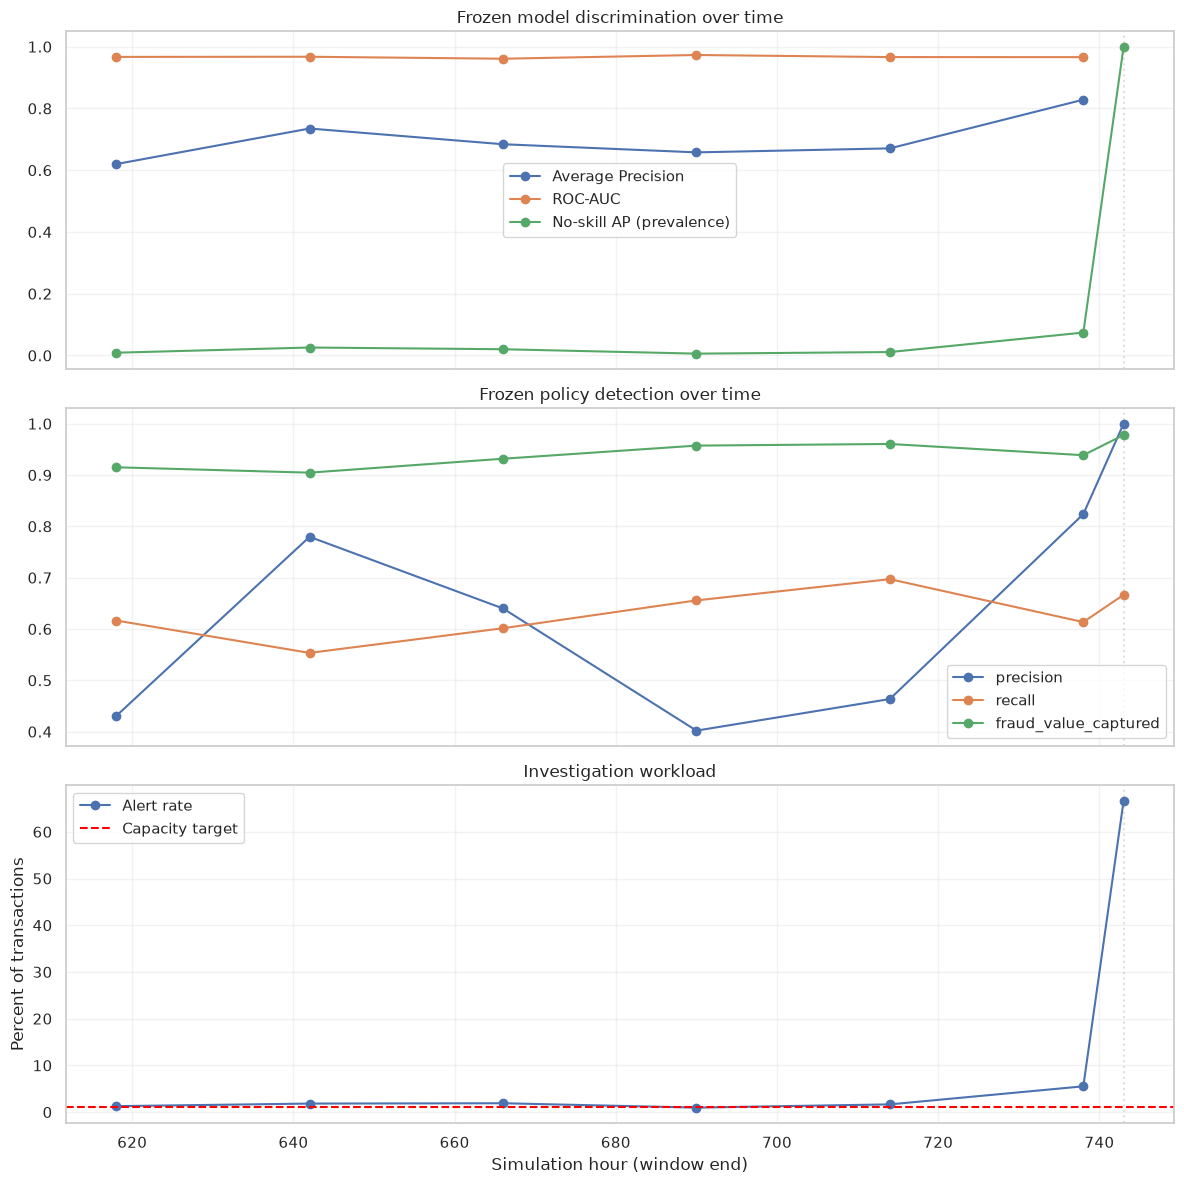

In [8]:
fig, axes = plt.subplots(
    3, 1,
    figsize=(12, 12),
    sharex=True
)

for metric, label in [
    ("average_precision", "Average Precision"),
    ("roc_auc", "ROC-AUC"),
    ("fraud_rate", "No-skill AP (prevalence)")
]:

    axes[0].plot(
        window_results.end_step,
        window_results[metric],
        marker="o",
        label=label
    )

for metric in [
    "precision",
    "recall",
    "fraud_value_captured"
]:

    axes[1].plot(
        window_results.end_step,
        window_results[metric],
        marker="o",
        label=metric
    )

axes[2].plot(
    window_results.end_step,
    100 * window_results.alert_rate,
    marker="o",
    label="Alert rate"
)

axes[2].axhline(
    100 * MAX_ALERT_RATE,
    ls="--",
    color="red",
    label="Capacity target"
)

for ax in axes:

    ax.legend()
    ax.grid(alpha=.25)

    for end in window_results.loc[
        window_results.low_support
        | window_results.partial_window,
        "end_step"
    ]:

        ax.axvline(
            end,
            color="gray",
            alpha=.25,
            linestyle=":"
        )

axes[0].set_title(
    "Frozen model discrimination over time"
)

axes[1].set_title(
    "Frozen policy detection over time"
)

axes[2].set_title(
    "Investigation workload"
)

axes[2].set_ylabel("Percent of transactions")
axes[2].set_xlabel("Simulation hour (window end)")

save_plot("temporal_window_performance.png")

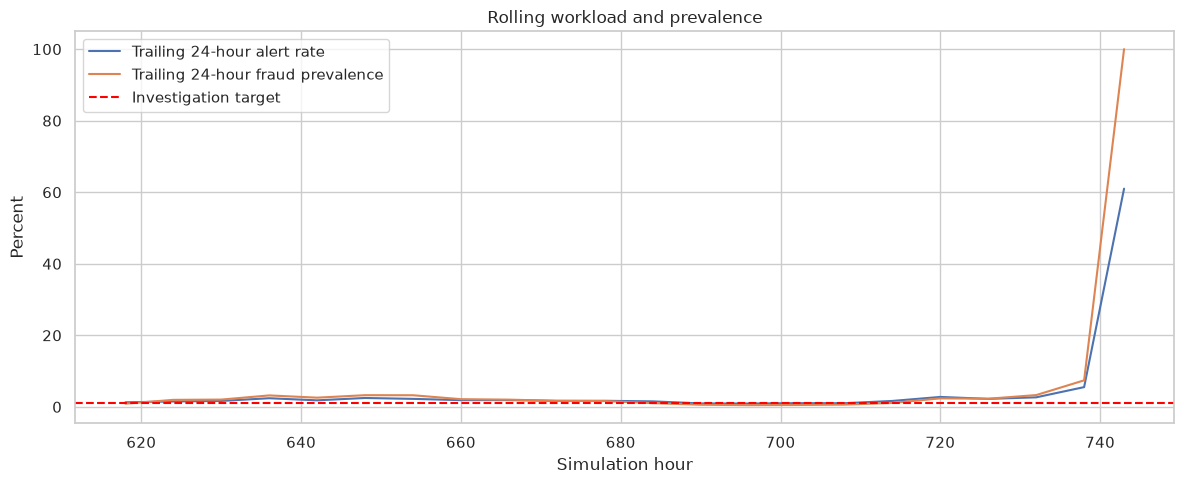

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    rolling_results.end_step,
    100 * rolling_results.alert_rate,
    label="Trailing 24-hour alert rate"
)

plt.plot(
    rolling_results.end_step,
    100 * rolling_results.fraud_rate,
    label="Trailing 24-hour fraud prevalence"
)

plt.axhline(
    100 * MAX_ALERT_RATE,
    ls="--",
    color="red",
    label="Investigation target"
)

plt.xlabel("Simulation hour")
plt.ylabel("Percent")
plt.title("Rolling workload and prevalence")
plt.legend()

save_plot("temporal_rolling_workload.png")

In [10]:
DISCRETE_FEATURES = {
    "type",
    "recipient_is_merchant",
    "recipient_is_new"
}


def fit_psi_spec(
    series,
    categorical=False,
    n_bins=PSI_BINS
):

    if categorical:

        categories = sorted(
            series.dropna()
            .astype(str)
            .unique()
            .tolist()
        )

        return {
            "kind": "categorical",
            "categories": categories,
            "labels": [
                "value=" + v for v in categories
            ] + ["OTHER", "MISSING"]
        }

    values = pd.to_numeric(
        series,
        errors="coerce"
    ).to_numpy(
        dtype=float,
        na_value=np.nan
    )

    finite = values[np.isfinite(values)]

    if not len(finite):

        return {
            "kind": "all_missing",
            "labels": [
                "FINITE_UNSEEN",
                "MISSING"
            ]
        }

    lo = float(finite.min())
    hi = float(finite.max())

    edges = np.unique(
        np.quantile(
            finite,
            np.linspace(0, 1, n_bins + 1)
        )
    )

    edges = edges[
        (edges > lo) & (edges < hi)
    ].tolist()

    return {
        "kind": "numeric",
        "min": lo,
        "max": hi,
        "edges": edges,

        "labels": (
            ["BELOW_MIN"]
            + [
                f"bin_{i}"
                for i in range(len(edges) + 1)
            ]
            + ["ABOVE_MAX", "MISSING"]
        )
    }


def psi_counts(series, spec):

    size = len(spec["labels"])

    if spec["kind"] == "categorical":

        lookup = {
            v: i
            for i, v in enumerate(
                spec["categories"]
            )
        }

        missing = series.isna().to_numpy()

        indices = np.array([
            lookup.get(v, size - 2)
            for v in series.astype(str)
        ], dtype=int)

        indices[missing] = size - 1

    else:

        x = pd.to_numeric(
            series,
            errors="coerce"
        ).to_numpy(
            dtype=float,
            na_value=np.nan
        )

        finite = np.isfinite(x)

        if spec["kind"] == "all_missing":

            indices = np.where(
                finite, 0, 1
            )

        else:

            indices = np.searchsorted(
                spec["edges"],
                x,
                side="right"
            ) + 1

            indices[x < spec["min"]] = 0

            indices[x > spec["max"]] = size - 2

            indices[~finite] = size - 1

    counts = np.bincount(
        indices,
        minlength=size
    )

    assert len(counts) == size
    assert counts.sum() == len(series)

    return counts


def smoothed_proportions(counts):

    counts = (
        np.asarray(counts, dtype=float)
        + PSI_PSEUDOCOUNT
    )

    return counts / counts.sum()


def calculate_psi(
    reference_counts,
    current_counts
):

    if (
        np.sum(reference_counts) == 0
        or np.sum(current_counts) == 0
    ):
        return np.nan

    p = smoothed_proportions(reference_counts)
    q = smoothed_proportions(current_counts)

    return float(
        np.sum(
            (q - p) * np.log(q / p)
        )
    )


def drift_status(psi, n_rows):

    if (
        n_rows < MIN_WINDOW_ROWS
        or not np.isfinite(psi)
    ):
        return "Insufficient data"

    if psi >= PSI_CRITICAL:
        return "Critical"

    if psi >= PSI_WARNING:
        return "Warning"

    return "Stable"

In [11]:
s = pd.Series([
    0, 0, 1, 1, np.nan
])

spec = fit_psi_spec(s)
c = psi_counts(s, spec)

assert calculate_psi(c, c) == 0

assert calculate_psi(
    c,
    psi_counts(
        pd.Series([10, 10, np.nan]),
        spec
    )
) > 0

spec_const = fit_psi_spec(
    pd.Series([5, 5, 5])
)

assert psi_counts(
    pd.Series([4, 5, 6, np.nan]),
    spec_const
).tolist() == [1, 1, 1, 1]

spec_cat = fit_psi_spec(
    pd.Series(["A", "B", None]),
    categorical=True
)

assert psi_counts(
    pd.Series(["C", None, "A"]),
    spec_cat
).tolist() == [1, 0, 1, 1]

print("PSI edge-case checks passed.")

PSI edge-case checks passed.


In [12]:
monitor_columns = feature_columns + [
    "raw_probability",
    "fraud_probability"
]

reference_profiles = {}

for col in monitor_columns:

    spec = fit_psi_spec(
        reference_df[col],
        categorical=col in DISCRETE_FEATURES
    )

    counts = psi_counts(
        reference_df[col],
        spec
    )

    reference_profiles[col] = {
        **spec,

        "reference_counts": counts.tolist(),

        "reference_proportions": (
            smoothed_proportions(counts).tolist()
        ),

        "reference_missing_rate": float(
            counts[-1] / counts.sum()
        )
    }


def compare_distributions(
    df,
    period_name,
    columns=monitor_columns
):

    rows = []

    for col in columns:

        spec = reference_profiles[col]

        counts = psi_counts(
            df[col],
            spec
        )

        psi = calculate_psi(
            spec["reference_counts"],
            counts
        )

        missing_rate = safe_divide(
            counts[-1],
            len(df)
        )

        delta = (
            missing_rate
            - spec["reference_missing_rate"]
        )

        rows.append({
            "period": period_name,
            "feature": col,
            "transactions": len(df),
            "psi": psi,

            "status": drift_status(
                psi, len(df)
            ),

            "reference_missing_rate": (
                spec["reference_missing_rate"]
            ),

            "missing_rate": missing_rate,

            "missing_rate_change": delta,

            "missingness_warning": bool(
                len(df) >= MIN_WINDOW_ROWS
                and abs(delta) >= MISSING_RATE_WARNING
            )
        })

    return pd.DataFrame(rows)


feature_drift = pd.concat([
    compare_distributions(df, name)
    for name, df in periods.items()
], ignore_index=True)

feature_drift.loc[
    feature_drift.period.eq("Test")
].sort_values(
    "psi",
    ascending=False
).round(6)

,period,feature,transactions,psi,status,reference_missing_rate,missing_rate,missing_rate_change,missingness_warning
37,Test,recipient_hours_since_last,123580,0.784322,Critical,0.441738,0.450138,0.0084,False
32,Test,hour_sin,123580,0.471263,Critical,0.000000,0.000000,0.0000,False
41,Test,fraud_probability,123580,0.074001,Stable,0.000000,0.000000,0.0000,False
40,Test,raw_probability,123580,0.074001,Stable,0.000000,0.000000,0.0000,False
33,Test,hour_cos,123580,0.049309,Stable,0.000000,0.000000,0.0000,False
30,Test,log_amount,123580,0.000951,Stable,0.000000,0.000000,0.0000,False
29,Test,amount,123580,0.000951,Stable,0.000000,0.000000,0.0000,False
28,Test,type,123580,0.000718,Stable,0.000000,0.000000,0.0000,False
35,Test,recipient_prior_total,123580,0.000608,Stable,0.000000,0.000000,0.0000,False
36,Test,recipient_prior_mean,123580,0.000556,Stable,0.441738,0.450138,0.0084,False


In [13]:
window_drift = pd.concat([
    compare_distributions(
        df,
        f"{lo}-{hi}"
    ).assign(
        start_step=lo,
        end_step=hi,
        partial_window=(
            hi - lo + 1 < WINDOW_HOURS
        )
    )

    for lo, hi, df in fixed_windows

], ignore_index=True)

window_drift.head()

,period,feature,transactions,psi,status,reference_missing_rate,missing_rate,missing_rate_change,missingness_warning,start_step,end_step,partial_window
0,595-618,type,29943,0.006627,Stable,0.0,0.0,0.0,False,595,618,False
1,595-618,amount,29943,0.028941,Stable,0.0,0.0,0.0,False,595,618,False
2,595-618,log_amount,29943,0.028941,Stable,0.0,0.0,0.0,False,595,618,False
3,595-618,recipient_is_merchant,29943,0.004376,Stable,0.0,0.0,0.0,False,595,618,False
4,595-618,hour_sin,29943,1.918554,Critical,0.0,0.0,0.0,False,595,618,False


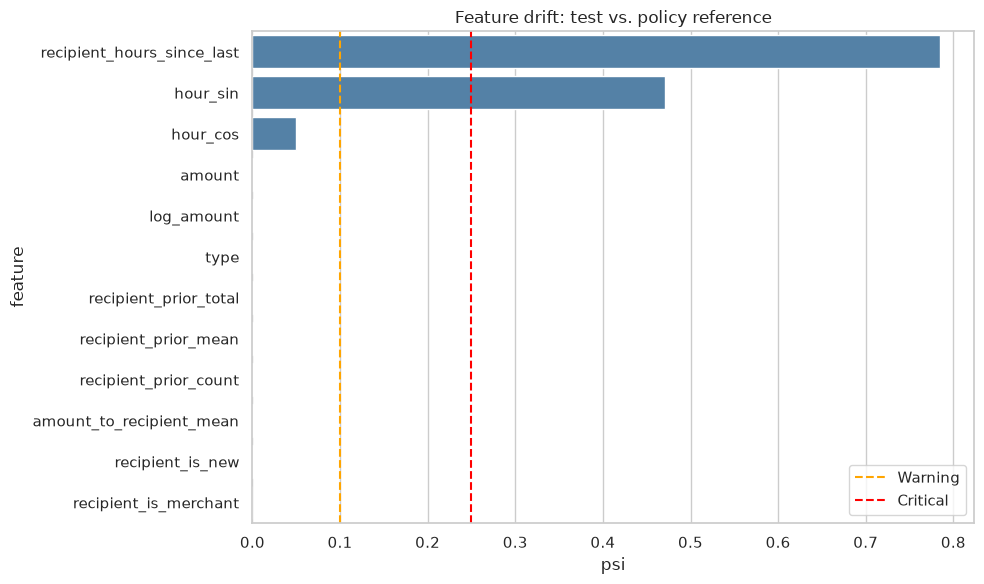

In [14]:
plot_drift = feature_drift.loc[
    feature_drift.period.eq("Test")
    & feature_drift.feature.isin(feature_columns)
]

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_drift.sort_values(
        "psi",
        ascending=False
    ),
    x="psi",
    y="feature",
    color="steelblue"
)

plt.axvline(
    PSI_WARNING,
    color="orange",
    ls="--",
    label="Warning"
)

plt.axvline(
    PSI_CRITICAL,
    color="red",
    ls="--",
    label="Critical"
)

plt.legend()
plt.title("Feature drift: test vs. policy reference")

save_plot("temporal_feature_drift.png")

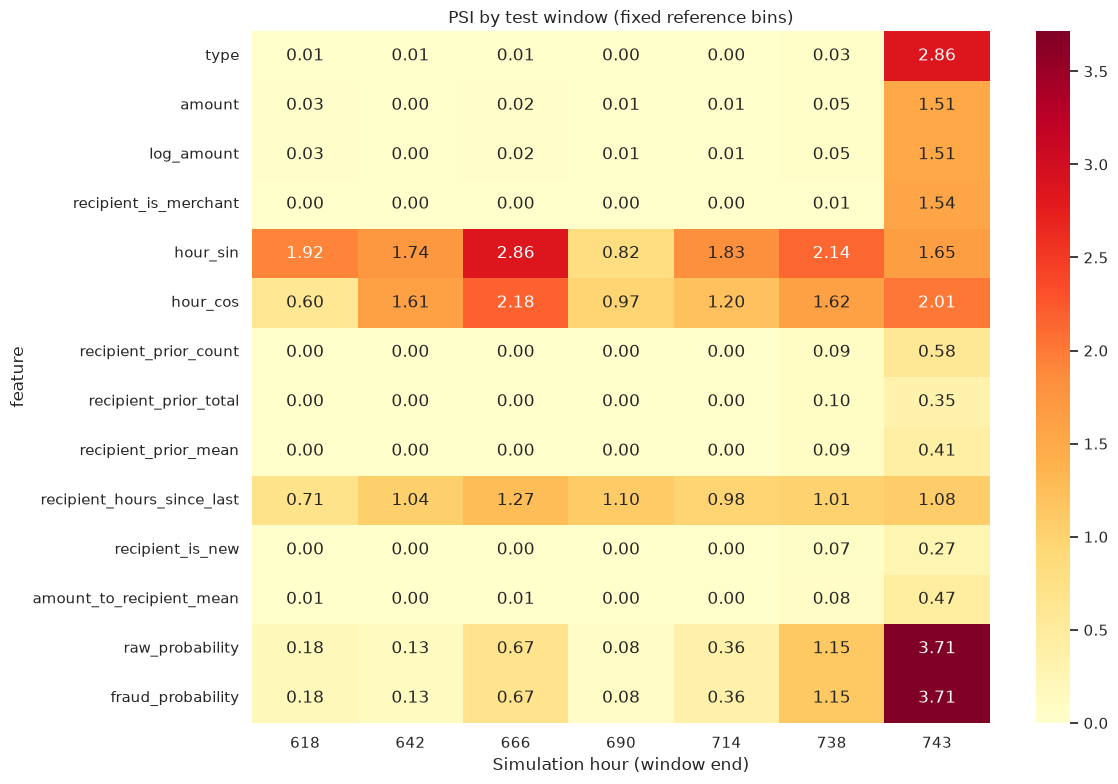

In [15]:
heatmap_data = window_drift.pivot(
    index="feature",
    columns="end_step",
    values="psi"
).reindex(monitor_columns)

plt.figure(figsize=(12, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".2f",
    cmap="YlOrRd",
    vmin=0
)

plt.title("PSI by test window (fixed reference bins)")
plt.xlabel("Simulation hour (window end)")

save_plot("temporal_psi_heatmap.png")

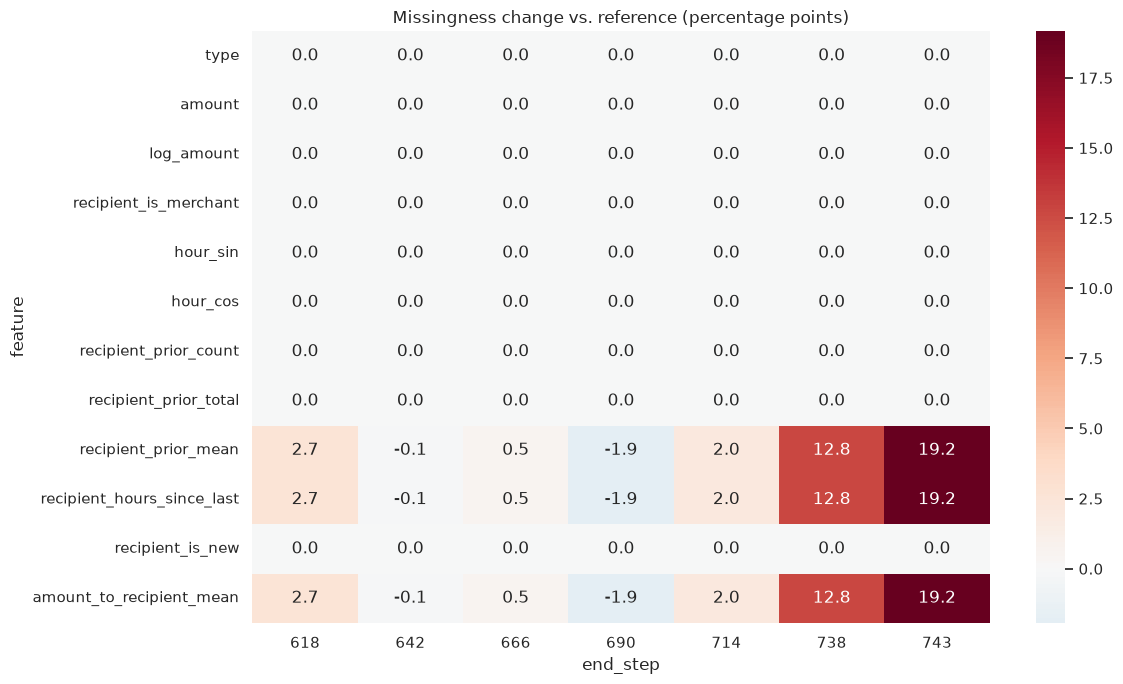

In [16]:
missingness_table = window_drift.pivot(
    index="feature",
    columns="end_step",
    values="missing_rate_change"
).reindex(feature_columns)

plt.figure(figsize=(12, 7))

sns.heatmap(
    100 * missingness_table,
    center=0,
    cmap="RdBu_r",
    annot=True,
    fmt=".1f"
)

plt.title(
    "Missingness change vs. reference "
    "(percentage points)"
)

save_plot("temporal_missingness_drift.png")

In [17]:
type_mix = pd.crosstab(
    pd.concat([
        df.assign(period=name)[["period", "type"]]
        for name, df in periods.items()
    ], ignore_index=True)["period"],

    pd.concat([
        df["type"]
        for df in periods.values()
    ], ignore_index=True),

    normalize="index"

).reindex(list(periods))

type_mix

type,CASH_IN,CASH_OUT,DEBIT,PAYMENT,TRANSFER
period,,,,,
Calibration,0.229447,0.310261,0.006218,0.355651,0.098423
Policy reference,0.226101,0.325839,0.008265,0.348891,0.090904
Test,0.229633,0.317665,0.008003,0.347362,0.097338


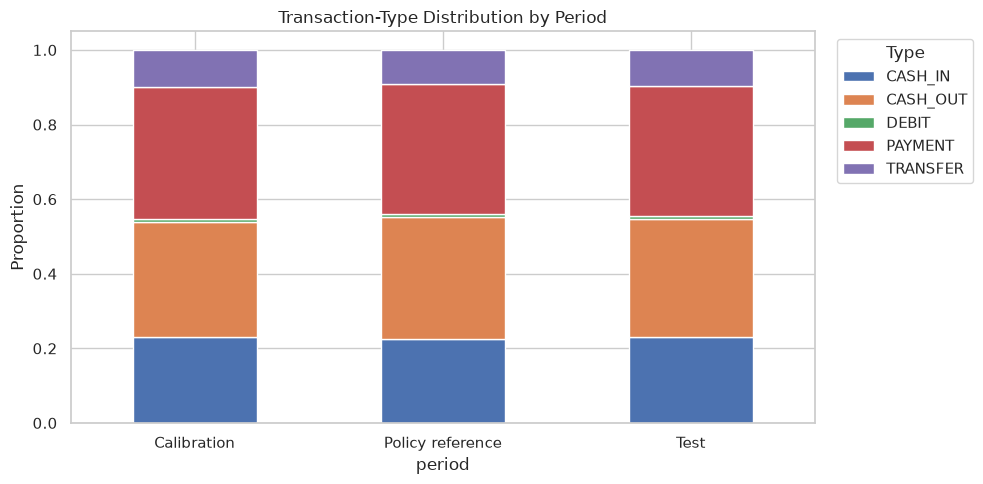

In [18]:
type_mix.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)

plt.title("Transaction-Type Distribution by Period")
plt.ylabel("Proportion")
plt.xticks(rotation=0)

plt.legend(
    title="Type",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

save_plot("temporal_transaction_mix.png")

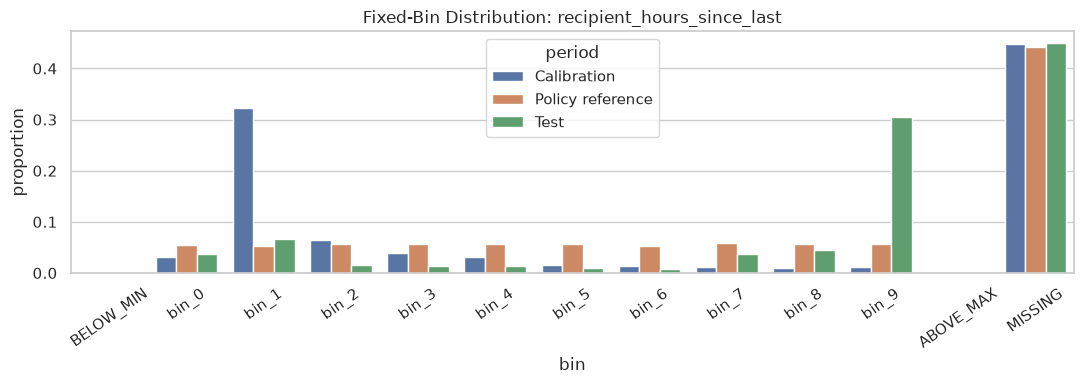

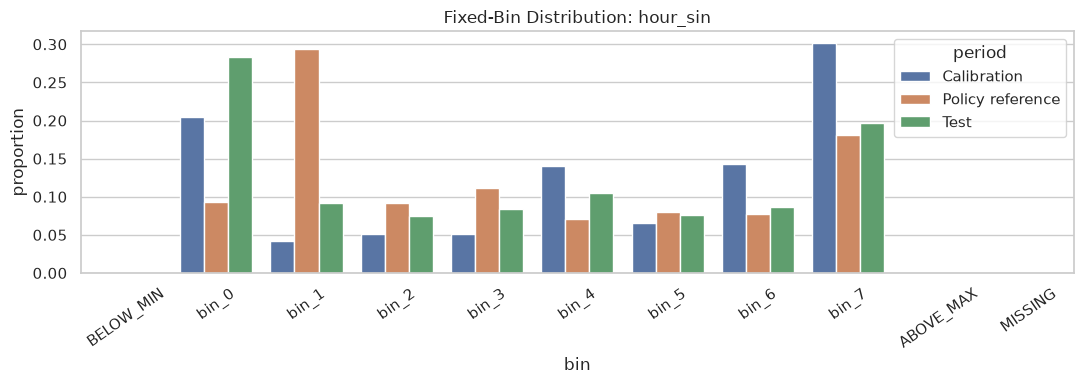

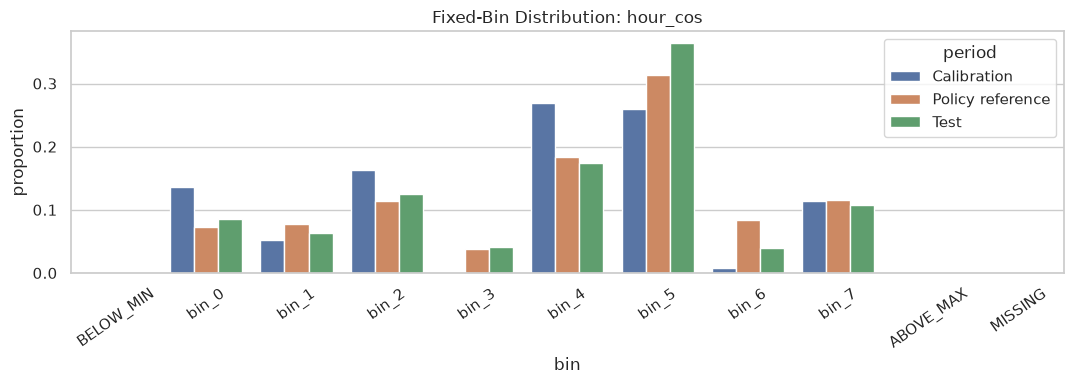

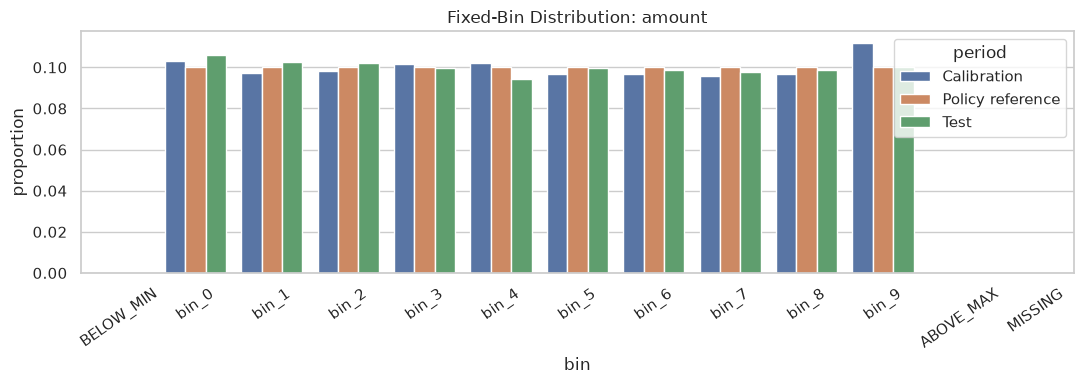

In [19]:
top_drift_features = plot_drift.nlargest(
    4, "psi"
)["feature"].tolist()

bin_details = []

for col in top_drift_features:

    spec = reference_profiles[col]

    for name, df in periods.items():

        counts = psi_counts(
            df[col],
            spec
        )

        for label, count in zip(
            spec["labels"],
            counts
        ):

            bin_details.append({
                "feature": col,
                "period": name,
                "bin": label,
                "count": int(count),
                "proportion": count / len(df)
            })

bin_details_df = pd.DataFrame(bin_details)

for col in top_drift_features:

    data = bin_details_df.loc[
        bin_details_df.feature.eq(col)
    ]

    plt.figure(figsize=(11, 4))

    sns.barplot(
        data=data,
        x="bin",
        y="proportion",
        hue="period",
        order=reference_profiles[col]["labels"]
    )

    plt.title(f"Fixed-Bin Distribution: {col}")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

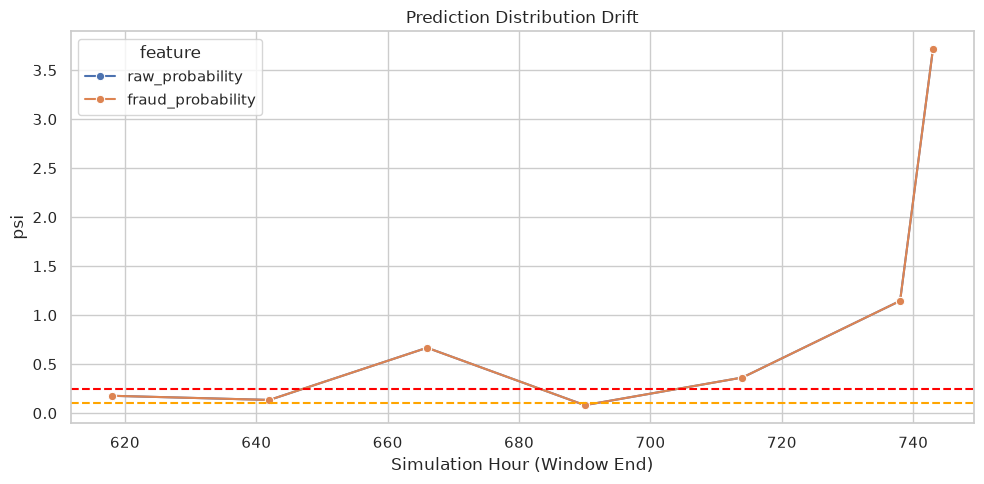

In [20]:
score_drift = window_drift.loc[
    window_drift.feature.isin([
        "raw_probability",
        "fraud_probability"
    ])
].copy()

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=score_drift,
    x="end_step",
    y="psi",
    hue="feature",
    marker="o"
)

plt.axhline(
    PSI_WARNING,
    color="orange",
    ls="--"
)

plt.axhline(
    PSI_CRITICAL,
    color="red",
    ls="--"
)

plt.title("Prediction Distribution Drift")
plt.xlabel("Simulation Hour (Window End)")

save_plot("temporal_prediction_drift.png")

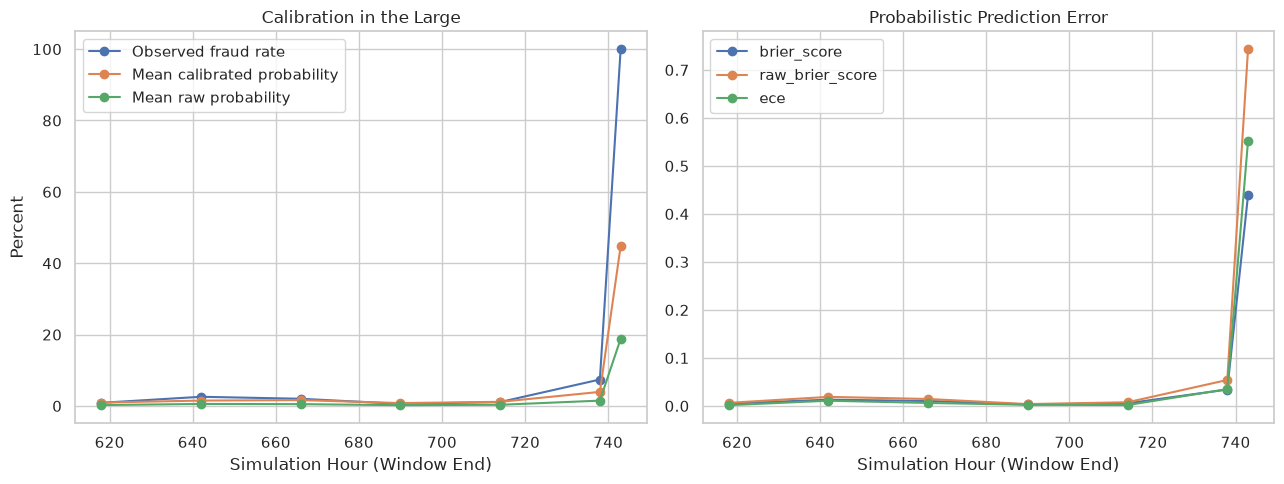

In [21]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5)
)

axes[0].plot(
    window_results.end_step,
    100 * window_results.fraud_rate,
    marker="o",
    label="Observed fraud rate"
)

axes[0].plot(
    window_results.end_step,
    100 * window_results.mean_probability,
    marker="o",
    label="Mean calibrated probability"
)

axes[0].plot(
    window_results.end_step,
    100 * window_results.mean_raw_probability,
    marker="o",
    label="Mean raw probability"
)

axes[0].set_ylabel("Percent")
axes[0].legend()
axes[0].set_title("Calibration in the Large")

for col in [
    "brier_score",
    "raw_brier_score",
    "ece"
]:

    axes[1].plot(
        window_results.end_step,
        window_results[col],
        marker="o",
        label=col
    )

axes[1].set_title("Probabilistic Prediction Error")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("Simulation Hour (Window End)")

save_plot("temporal_calibration_drift.png")

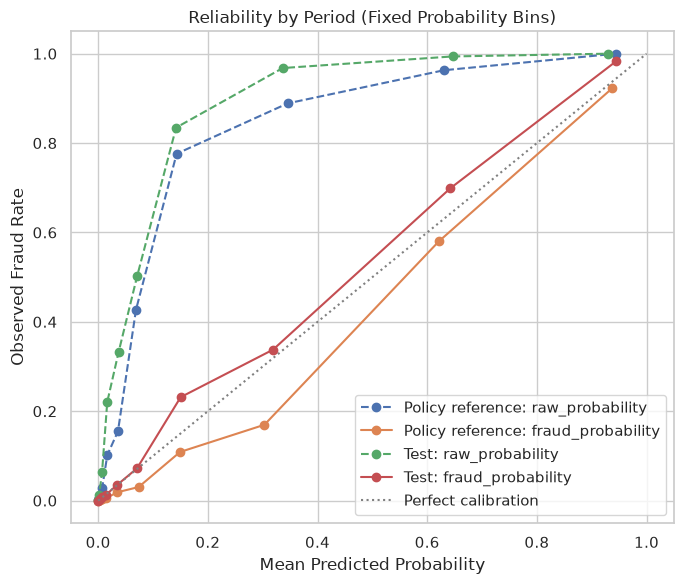

In [22]:
reliability_results = pd.concat([
    calibration_bins(
        df[target_column],
        df[probability_col]
    ).assign(
        period=name,
        score=probability_col
    )

    for name, df in periods.items()

    for probability_col in [
        "raw_probability",
        "fraud_probability"
    ]

], ignore_index=True)

plt.figure(figsize=(7, 6))

for name in [
    "Policy reference",
    "Test"
]:

    for col, style in [
        ("raw_probability", "--"),
        ("fraud_probability", "-")
    ]:

        bins = reliability_results.loc[
            (reliability_results.period == name)
            & (reliability_results.score == col)
            & (reliability_results["count"] > 0)
        ]

        plt.plot(
            bins.mean_probability,
            bins.observed_fraud_rate,
            marker="o",
            ls=style,
            label=f"{name}: {col}"
        )

plt.plot(
    [0, 1],
    [0, 1],
    color="gray",
    ls=":",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Fraud Rate")
plt.title("Reliability by Period (Fixed Probability Bins)")
plt.legend()

save_plot("temporal_reliability.png")

In [23]:
capacity_results = window_results[[
    "start_step",
    "end_step",
    "window_hours",
    "partial_window",
    "transactions",
    "alert_count",
    "alert_rate",
    "high_risk_rate",
    "capacity_exceeded",
    "excess_alerts"
]].copy()

capacity_results["review_capacity"] = np.floor(
    MAX_ALERT_RATE
    * capacity_results.transactions
    + 1e-9
).astype(int)

capacity_results["high_risk_target_exceeded"] = (
    capacity_results.high_risk_rate
    > HIGH_RISK_ALERT_RATE
)

capacity_results

,start_step,end_step,window_hours,partial_window,transactions,alert_count,alert_rate,high_risk_rate,capacity_exceeded,excess_alerts,review_capacity,high_risk_target_exceeded
0,595,618,24,False,29943,381,0.012724,0.001870,True,82,299,True
1,619,642,24,False,10192,186,0.018250,0.005200,True,85,101,True
2,643,666,24,False,13189,250,0.018955,0.004019,True,119,131,True
3,667,690,24,False,41489,398,0.009593,0.001591,False,0,414,True
4,691,714,24,False,24902,412,0.016545,0.002851,True,163,249,True
5,715,738,24,False,3805,210,0.055191,0.014717,True,172,38,True
6,739,743,5,True,60,40,0.666667,0.166667,True,40,0,True


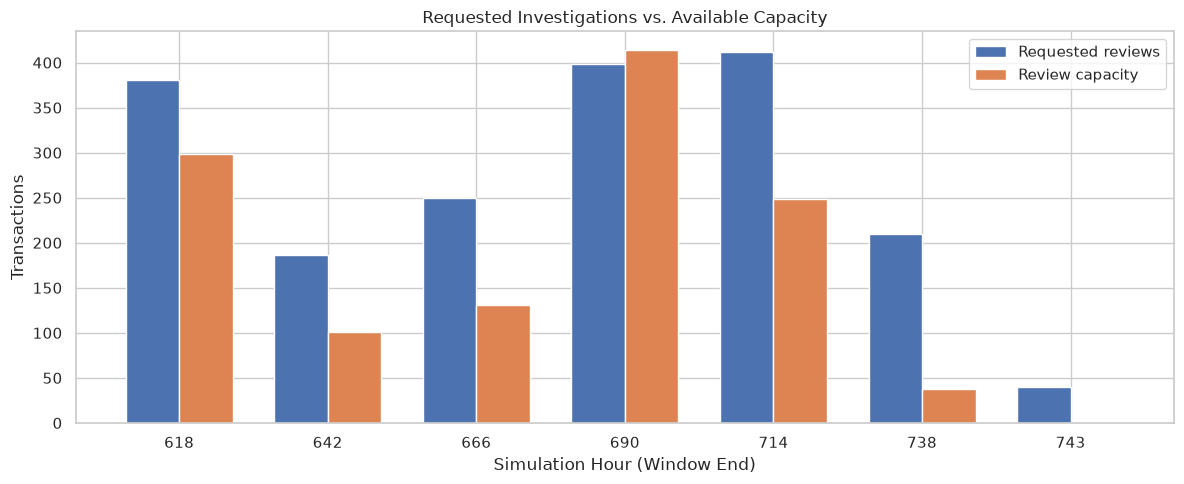

Windows exceeding target: 6 / 7
Total excess reviews across windows: 661


In [24]:
plt.figure(figsize=(12, 5))

x = np.arange(len(capacity_results))

plt.bar(
    x - .18,
    capacity_results.alert_count,
    width=.36,
    label="Requested reviews"
)

plt.bar(
    x + .18,
    capacity_results.review_capacity,
    width=.36,
    label="Review capacity"
)

plt.xticks(
    x,
    capacity_results.end_step
)

plt.xlabel("Simulation Hour (Window End)")
plt.ylabel("Transactions")

plt.title(
    "Requested Investigations vs. Available Capacity"
)

plt.legend()

save_plot("temporal_capacity_violations.png")

print(
    "Windows exceeding target:",
    int(capacity_results.capacity_exceeded.sum()),
    "/",
    len(capacity_results)
)

print(
    "Total excess reviews across windows:",
    int(capacity_results.excess_alerts.sum())
)

In [25]:
def capped_reviews(df, ranking):

    n = len(df)

    capacity = int(
        np.floor(
            MAX_ALERT_RATE * n + 1e-9
        )
    )

    eligible = np.flatnonzero(
        df["prediction"].to_numpy() == 1
    )

    p = df["fraud_probability"].to_numpy(
        dtype=float
    )

    if ranking == "probability":

        priority = p

    elif ranking == "expected_value":

        priority = (
            p
            * df["amount"].to_numpy(dtype=float)
            * PREVENTABLE_FRACTION
        )

    else:

        raise ValueError("Unknown ranking")

    chosen = eligible[
        np.argsort(
            -priority[eligible],
            kind="stable"
        )[:capacity]
    ]

    decisions = np.zeros(
        n,
        dtype=bool
    )

    decisions[chosen] = True

    assert decisions.sum() <= capacity

    assert np.all(
        ~decisions
        | (df["prediction"].to_numpy() == 1)
    )

    return decisions

queue_results = []

queue_predictions = {
    name: np.zeros(len(test_df), dtype=bool)

    for name in [
        "Frozen threshold",
        "Capped probability",
        "Capped expected value"
    ]
}

for lo, hi, df in fixed_windows:

    decisions = {
        "Frozen threshold": (
            df.prediction.to_numpy(dtype=bool)
        ),

        "Capped probability": capped_reviews(
            df,
            "probability"
        ),

        "Capped expected value": capped_reviews(
            df,
            "expected_value"
        )
    }

    for name, pred in decisions.items():

        queue_predictions[name][
            df.index.to_numpy()
        ] = pred

        queue_results.append({
            "policy": name,

            "start_step": lo,
            "end_step": hi,

            "review_capacity": int(
                np.floor(
                    MAX_ALERT_RATE * len(df)
                    + 1e-9
                )
            ),

            **evaluate_window(df, pred)
        })

queue_window_results = pd.DataFrame(
    queue_results
)

queue_summary = pd.DataFrame([
    {
        "policy": name,
        **evaluate_window(test_df, pred)
    }

    for name, pred in queue_predictions.items()
])

assert np.array_equal(
    queue_predictions["Frozen threshold"],
    test_df.prediction.to_numpy(dtype=bool)
)

assert not queue_window_results.loc[
    queue_window_results.policy.ne(
        "Frozen threshold"
    ),
    "capacity_exceeded"
].any()

queue_summary[[
    "policy",
    "alert_count",
    "alert_rate",
    "precision",
    "recall",
    "fraud_value_captured",
    "hypothetical_total_cost",
    "hypothetical_savings"
]].round(6)

,policy,alert_count,alert_rate,precision,recall,fraud_value_captured,hypothetical_total_cost,hypothetical_savings
0,Frozen threshold,1877,0.015189,0.550346,0.624547,0.939845,1.656451e+07,2.556789e+08
1,Capped probability,1216,0.009840,0.586349,0.431076,0.742315,7.027478e+07,2.019687e+08
2,Capped expected value,1216,0.009840,0.577303,0.424426,0.837139,4.445956e+07,2.277839e+08


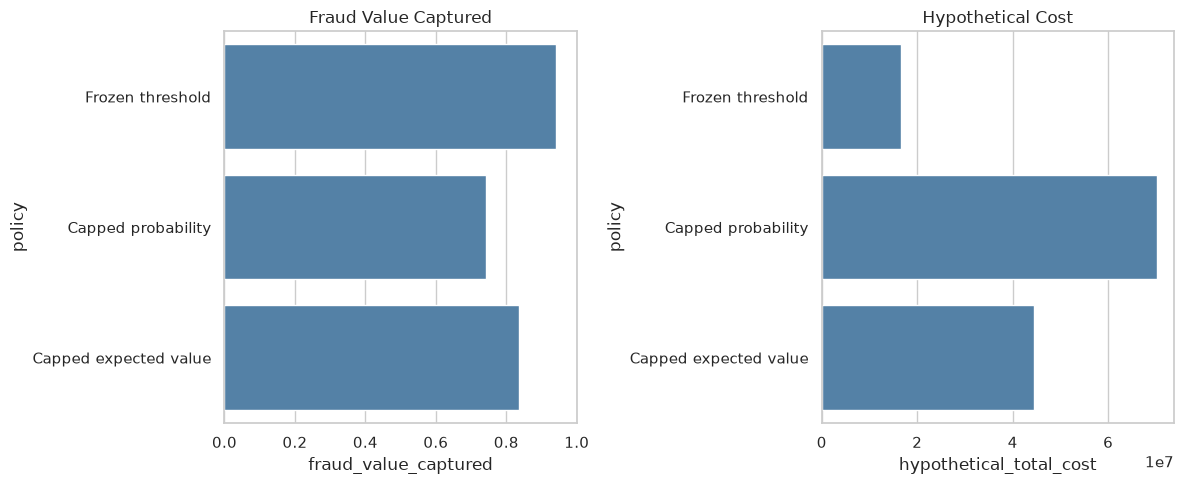

In [26]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

sns.barplot(
    data=queue_summary,
    x="fraud_value_captured",
    y="policy",
    ax=axes[0],
    color="steelblue"
)

axes[0].set_xlim(0, 1)
axes[0].set_title("Fraud Value Captured")

sns.barplot(
    data=queue_summary,
    x="hypothetical_total_cost",
    y="policy",
    ax=axes[1],
    color="steelblue"
)

axes[1].set_title("Hypothetical Cost")

save_plot(
    "temporal_capacity_policy_comparison.png"
)

In [27]:
subgroup_rows = []

for period_name in [
    "Policy reference",
    "Test"
]:

    df = periods[period_name]

    for col in [
        "type",
        "recipient_is_new"
    ]:

        for value, subset in df.groupby(
            col,
            observed=True,
            dropna=False
        ):

            subgroup_rows.append({
                "period": period_name,

                "group_feature": col,

                "group_value": str(value),

                **evaluate_window(subset)
            })

subgroup_results = pd.DataFrame(
    subgroup_rows
)

subgroup_results[[
    "period",
    "group_feature",
    "group_value",
    "transactions",
    "fraud_count",
    "fraud_rate",
    "precision",
    "recall",
    "alert_rate",
    "fraud_value_captured",
    "low_support"
]].round(6)

,period,group_feature,group_value,transactions,fraud_count,fraud_rate,precision,recall,alert_rate,fraud_value_captured,low_support
0,Policy reference,type,CASH_IN,36192,0,0.000000,NaN,NaN,0.000000,NaN,True
1,Policy reference,type,CASH_OUT,52157,395,0.007573,0.415709,0.549367,0.010008,0.921507,False
2,Policy reference,type,DEBIT,1323,0,0.000000,NaN,NaN,0.000000,NaN,True
3,Policy reference,type,PAYMENT,55847,0,0.000000,NaN,NaN,0.000000,NaN,True
4,Policy reference,type,TRANSFER,14551,395,0.027146,0.277052,0.751899,0.073672,0.938173,False
5,Policy reference,recipient_is_new,0,89361,298,0.003335,0.336887,0.530201,0.005248,0.912517,False
6,Policy reference,recipient_is_new,1,70709,492,0.006958,0.316444,0.723577,0.015910,0.939468,False
7,Test,type,CASH_IN,28378,0,0.000000,NaN,NaN,0.000000,NaN,True
8,Test,type,CASH_OUT,39257,827,0.021066,0.835564,0.528416,0.013322,0.937972,False
9,Test,type,DEBIT,989,0,0.000000,NaN,NaN,0.000000,NaN,True


In [28]:
preprocessor = model.named_steps[
    "preprocessor"
]

classifier = model.named_steps[
    "classifier"
]

feature_names = (
    preprocessor.get_feature_names_out().tolist()
)

booster = classifier.get_booster()

try:

    best_iteration = classifier.best_iteration

except AttributeError:

    best_iteration = (
        booster.num_boosted_rounds() - 1
    )

inference_booster = booster[
    :best_iteration + 1
]

inference_booster.set_param({
    "nthread": N_JOBS
})

def grouped_shap_contributions(df):

    processed = preprocessor.transform(
        df[feature_columns]
    )

    matrix = xgb.DMatrix(
        processed,
        feature_names=feature_names
    )

    contributions = inference_booster.predict(
        matrix,
        pred_contribs=True
    )

    values = contributions[:, :-1]

    base = contributions[:, -1]

    np.testing.assert_allclose(
        values.sum(axis=1) + base,

        classifier.predict(
            processed,
            output_margin=True
        ),

        rtol=1e-5,
        atol=1e-4
    )

    grouped = {}

    for col in feature_columns:

        if col == "type":

            indices = [
                i
                for i, name in enumerate(
                    feature_names
                )
                if name.startswith("type_")
            ]

        else:

            indices = [
                feature_names.index(col)
            ]

        assert indices

        grouped[col] = (
            values[:, indices].sum(axis=1)
        )

    result = pd.DataFrame(grouped)

    np.testing.assert_allclose(
        result.sum(axis=1),
        values.sum(axis=1),
        rtol=1e-5,
        atol=1e-4
    )

    return result

n_shap = min(
    SHAP_SAMPLE_SIZE,
    len(reference_df),
    len(test_df)
)

reference_shap = grouped_shap_contributions(
    reference_df.sample(
        n=n_shap,
        random_state=RANDOM_STATE
    )
)

test_shap = grouped_shap_contributions(
    test_df.sample(
        n=n_shap,
        random_state=RANDOM_STATE
    )
)

shap_drift_rows = []

for col in feature_columns:

    spec = fit_psi_spec(
        reference_shap[col]
    )

    psi = calculate_psi(
        psi_counts(reference_shap[col], spec),
        psi_counts(test_shap[col], spec)
    )

    shap_drift_rows.append({
        "feature": col,

        "reference_mean_abs_shap": (
            reference_shap[col].abs().mean()
        ),

        "test_mean_abs_shap": (
            test_shap[col].abs().mean()
        ),

        "reference_mean_signed_shap": (
            reference_shap[col].mean()
        ),

        "test_mean_signed_shap": (
            test_shap[col].mean()
        ),

        "shap_psi": psi,

        "status": drift_status(
            psi, n_shap
        )
    })

shap_drift = pd.DataFrame(
    shap_drift_rows
)

shap_drift["absolute_importance_change"] = (
    shap_drift.test_mean_abs_shap
    - shap_drift.reference_mean_abs_shap
)

shap_drift.sort_values(
    "shap_psi",
    ascending=False
).round(6)

,feature,reference_mean_abs_shap,test_mean_abs_shap,reference_mean_signed_shap,test_mean_signed_shap,shap_psi,status,absolute_importance_change
9,recipient_hours_since_last,0.112182,0.140771,0.091215,0.125137,0.293157,Critical,0.028588
1,amount,0.377887,0.390921,-0.255146,-0.249066,0.100671,Warning,0.013034
5,hour_cos,0.425995,0.399144,-0.042103,-0.033487,0.094400,Stable,-0.026851
4,hour_sin,0.263568,0.317240,-0.106496,-0.057560,0.082147,Stable,0.053672
3,recipient_is_merchant,0.106959,0.110024,-0.066284,-0.070398,0.059379,Stable,0.003065
0,type,1.460984,1.508673,-0.851894,-0.885978,0.057262,Stable,0.047689
11,amount_to_recipient_mean,0.249807,0.256593,-0.056318,-0.035616,0.035998,Stable,0.006785
2,log_amount,0.068757,0.072780,-0.054955,-0.055201,0.031874,Stable,0.004023
6,recipient_prior_count,0.202912,0.204043,-0.106192,-0.094244,0.016427,Stable,0.001131
7,recipient_prior_total,0.030399,0.030031,0.010665,0.011770,0.008483,Stable,-0.000368


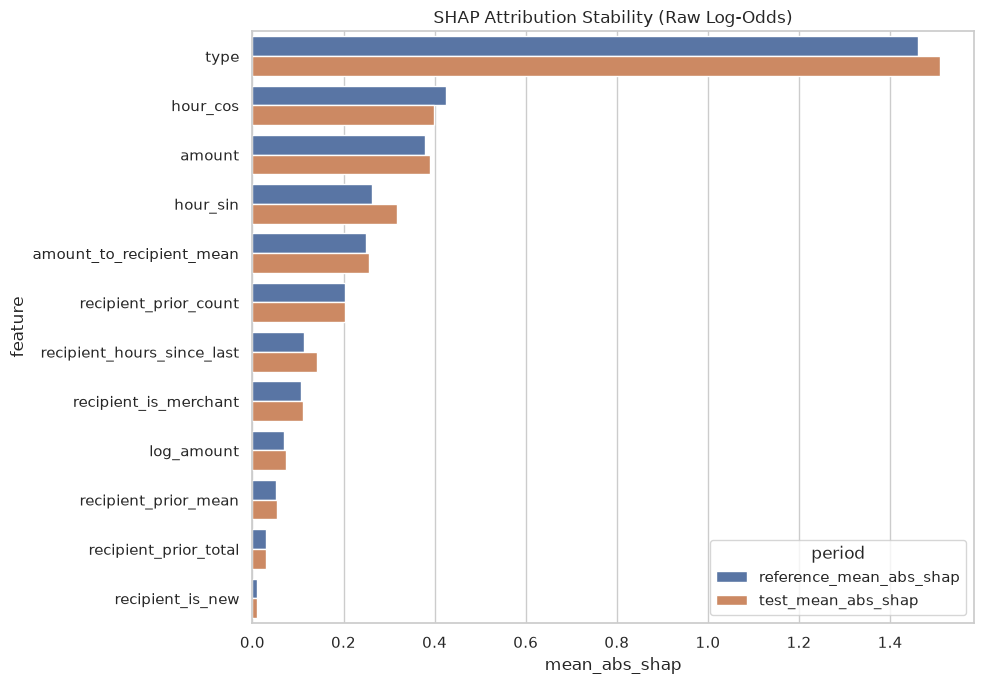

In [29]:
importance_long = shap_drift.melt(
    id_vars="feature",

    value_vars=[
        "reference_mean_abs_shap",
        "test_mean_abs_shap"
    ],

    var_name="period",

    value_name="mean_abs_shap"
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_long,
    x="mean_abs_shap",
    y="feature",
    hue="period",

    order=shap_drift.sort_values(
        "reference_mean_abs_shap",
        ascending=False
    ).feature
)

plt.title(
    "SHAP Attribution Stability (Raw Log-Odds)"
)

save_plot("temporal_shap_drift.png")

In [30]:
alert_rows = []

for row in window_drift.itertuples(
    index=False
):

    if row.status in (
        "Warning",
        "Critical"
    ):

        alert_rows.append({
            "start_step": row.start_step,
            "end_step": row.end_step,

            "monitor": row.feature,

            "alert_type": "distribution_drift",

            "severity": row.status,

            "value": row.psi,

            "limit": (
                PSI_CRITICAL
                if row.status == "Critical"
                else PSI_WARNING
            )
        })

    if row.missingness_warning:

        alert_rows.append({
            "start_step": row.start_step,
            "end_step": row.end_step,

            "monitor": row.feature,

            "alert_type": "missingness_drift",

            "severity": "Warning",

            "value": row.missing_rate_change,

            "limit": MISSING_RATE_WARNING
        })

for row in capacity_results.itertuples(
    index=False
):

    if row.capacity_exceeded:

        alert_rows.append({
            "start_step": row.start_step,
            "end_step": row.end_step,

            "monitor": "alert_rate",

            "alert_type": "capacity_violation",

            "severity": "Warning",

            "value": row.alert_rate,

            "limit": MAX_ALERT_RATE
        })

    if row.high_risk_target_exceeded:

        alert_rows.append({
            "start_step": row.start_step,
            "end_step": row.end_step,

            "monitor": "high_risk_rate",

            "alert_type": (
                "priority_capacity_violation"
            ),

            "severity": "Warning",

            "value": row.high_risk_rate,

            "limit": HIGH_RISK_ALERT_RATE
        })

monitoring_alerts = pd.DataFrame(
    alert_rows,

    columns=[
        "start_step",
        "end_step",
        "monitor",
        "alert_type",
        "severity",
        "value",
        "limit"
    ]
)

monitoring_alerts.sort_values([
    "start_step",
    "alert_type",
    "monitor"
]).reset_index(drop=True)

,start_step,end_step,monitor,alert_type,severity,value,limit
0,595,618,alert_rate,capacity_violation,Warning,0.012724,0.010
1,595,618,fraud_probability,distribution_drift,Warning,0.177222,0.100
2,595,618,hour_cos,distribution_drift,Critical,0.597829,0.250
3,595,618,hour_sin,distribution_drift,Critical,1.918554,0.250
4,595,618,raw_probability,distribution_drift,Warning,0.177222,0.100
5,595,618,recipient_hours_since_last,distribution_drift,Critical,0.710869,0.250
6,595,618,high_risk_rate,priority_capacity_violation,Warning,0.001870,0.001
7,619,642,alert_rate,capacity_violation,Warning,0.018250,0.010
8,619,642,fraud_probability,distribution_drift,Warning,0.134912,0.100
9,619,642,hour_cos,distribution_drift,Critical,1.609484,0.250


In [31]:
monitoring_alerts.groupby([
    "alert_type",
    "severity"
]).size().rename(
    "alerts"
).reset_index()

,alert_type,severity,alerts
0,capacity_violation,Warning,6
1,distribution_drift,Critical,24
2,distribution_drift,Warning,4
3,missingness_drift,Warning,3
4,priority_capacity_violation,Warning,7


In [32]:
reports = {
    "temporal_period_results":
        period_results,

    "temporal_window_results":
        window_results,

    "temporal_rolling_results":
        rolling_results,

    "temporal_feature_drift":
        feature_drift,

    "temporal_window_drift":
        window_drift,

    "temporal_bin_details":
        bin_details_df,

    "temporal_score_drift":
        score_drift,

    "temporal_calibration_bins":
        reliability_results,

    "temporal_capacity_results":
        capacity_results,

    "temporal_queue_window_results":
        queue_window_results,

    "temporal_queue_summary":
        queue_summary,

    "temporal_subgroup_results":
        subgroup_results,

    "temporal_shap_drift":
        shap_drift,

    "temporal_monitoring_alerts":
        monitoring_alerts
}

for name, df in reports.items():

    df.to_csv(
        RESULTS_PATH / f"{name}.csv",
        index=False
    )

type_mix.to_csv(
    RESULTS_PATH / "temporal_transaction_type_mix.csv"
)

monitoring_config = {
    "schema_version": 1,

    "model_name": policy["model_name"],

    "model_sha256": artifact_hash,

    "decision_policy_sha256": policy_hash,

    "reference_period": {
        "start_step": int(
            reference_df.step.min()
        ),

        "end_step": int(
            reference_df.step.max()
        ),

        "transactions": len(reference_df)
    },

    "feature_columns": feature_columns,

    "decision_threshold": DECISION_THRESHOLD,

    "high_risk_threshold": HIGH_RISK_THRESHOLD,

    "maximum_alert_rate": MAX_ALERT_RATE,

    "high_risk_alert_rate": HIGH_RISK_ALERT_RATE,

    "window_hours": WINDOW_HOURS,

    "window_anchor": "start_of_monitoring_period",

    "rolling_stride_hours": ROLLING_STRIDE_HOURS,

    "minimum_window_rows": MIN_WINDOW_ROWS,

    "minimum_window_fraud": MIN_WINDOW_FRAUD,

    "psi_warning": PSI_WARNING,

    "psi_critical": PSI_CRITICAL,

    "psi_bins": PSI_BINS,

    "psi_pseudocount": PSI_PSEUDOCOUNT,

    "missing_rate_warning": MISSING_RATE_WARNING,

    "calibration_bin_edges": (
        CALIBRATION_EDGES.tolist()
    ),

    "reference_profiles": reference_profiles,

    "random_state": RANDOM_STATE,

    "automatic_retraining": False,

    "alert_thresholds_are_heuristic": True
}

with open(
    MODEL_PATH / "monitoring_reference.json",
    "w"
) as f:

    json.dump(
        monitoring_config,
        f,
        indent=4,
        allow_nan=False
    )

assert sha256_file(
    artifact_path
) == artifact_hash

assert sha256_file(
    MODEL_PATH / "decision_policy.json"
) == policy_hash

print(
    "Original model and decision policy unchanged."
)

print(
    "Exported",
    len(reports) + 1,
    "CSV reports and monitoring reference JSON."
)

Original model and decision policy unchanged.
Exported 15 CSV reports and monitoring reference JSON.


In [33]:
temporal_metadata = {
    "reference_start_step": int(
        reference_df.step.min()
    ),

    "reference_end_step": int(
        reference_df.step.max()
    ),

    "test_start_step": TEST_START,

    "test_end_step": TEST_END,

    "test_windows": len(window_results),

    "partial_windows": int(
        window_results.partial_window.sum()
    ),

    "low_support_windows": int(
        window_results.low_support.sum()
    ),

    "capacity_violation_windows": int(
        capacity_results.capacity_exceeded.sum()
    ),

    "excess_alerts_across_windows": int(
        capacity_results.excess_alerts.sum()
    ),

    "test_alert_rate": float(
        actual["alert_rate"]
    ),

    "test_average_precision": float(
        actual["average_precision"]
    ),

    "test_fraud_value_captured": float(
        actual["fraud_value_captured"]
    ),

    "monitoring_alert_count": len(
        monitoring_alerts
    ),

    "shap_sample_size_per_period": n_shap,

    "model_modified": False,

    "decision_policy_modified": False,

    "test_performance_reproduced": True,

    "evaluation_type": (
        "retrospective_monitoring_on_previously_evaluated_test"
    ),

    "queue_simulation_status": (
        "exploratory_not_selected_for_deployment"
    ),

    "financial_assumptions": "hypothetical"
}

with open(
    MODEL_PATH / "temporal_validation_metadata.json",
    "w"
) as f:

    json.dump(
        temporal_metadata,
        f,
        indent=4,
        allow_nan=False
    )

temporal_metadata

{'reference_start_step': 520,
 'reference_end_step': 594,
 'test_start_step': 595,
 'test_end_step': 743,
 'test_windows': 7,
 'partial_windows': 1,
 'low_support_windows': 1,
 'capacity_violation_windows': 6,
 'excess_alerts_across_windows': 661,
 'test_alert_rate': 0.015188541835248422,
 'test_average_precision': 0.6745537209756224,
 'test_fraud_value_captured': 0.9398449727559479,
 'monitoring_alert_count': 44,
 'shap_sample_size_per_period': 5000,
 'model_modified': False,
 'decision_policy_modified': False,
 'test_performance_reproduced': True,
 'evaluation_type': 'retrospective_monitoring_on_previously_evaluated_test',
 'queue_simulation_status': 'exploratory_not_selected_for_deployment',
 'financial_assumptions': 'hypothetical'}

## Key Findings

### Temporal Evaluation Strategy
- Evaluated the temporal robustness of the finalized calibrated XGBoost fraud detection model.
- Reused the previously trained classifier, fitted preprocessing pipeline, sigmoid probability calibrator, and cost-sensitive decision thresholds.
- Performed retrospective monitoring without retraining the model or adjusting its decision policy.
- Used the policy optimization period as the fixed monitoring reference population.
- Evaluated distribution changes and model performance across the subsequent chronological test period.

| Period | Simulation Hours | Transactions | Fraudulent Transactions | Fraud Rate |
|---|---|---:|---:|---:|
| Calibration | 446–519 | 68,033 | 762 | 1.1200% |
| Policy Reference | 520–594 | 160,070 | 790 | 0.4935% |
| Test | 595–743 | 123,580 | 1,654 | 1.3384% |

- Divided the test period into seven non-overlapping monitoring windows.
- Six windows contained 24 simulation hours.
- The final partial window contained five simulation hours.
- Evaluated 22 overlapping trailing 24-hour windows using a six-hour stride, including a final window ending at the last simulation hour.
- Defined minimum monitoring support requirements of 1,000 transactions and 20 fraudulent transactions for performance comparisons.
- Used the previously evaluated test dataset for diagnostic monitoring rather than a new independent estimate of generalization.

### Frozen Model Consistency
- Loaded the finalized shallow XGBoost classifier trained using a 10% legitimate transaction sample.
- Preserved the original 12 leakage-controlled predictive features.
- Preserved the investigation threshold of approximately 0.161681.
- Preserved the high-risk threshold of approximately 0.927988.
- Preserved the investigation capacity target of 1%.
- Preserved the high-priority investigation target of 0.1%.
- Reused the original sigmoid probability calibration transformation.
- Calculated SHA-256 fingerprints of the model artifact and decision policy before performing monitoring experiments.
- Successfully reproduced the final test metrics from the previous model evaluation notebook.
- Verified that the original model artifact and decision policy files remained unchanged after completing all experiments.

### Model Performance Across Chronological Periods

| Metric | Calibration | Policy Reference | Test |
|---|---:|---:|---:|
| Fraud Prevalence | 1.1200% | 0.4935% | 1.3384% |
| Average Precision | 0.648429 | 0.577365 | 0.674554 |
| ROC-AUC | 0.967737 | 0.968702 | 0.966435 |
| Precision | 44.25% | 32.25% | 55.03% |
| Recall | 65.09% | 65.06% | 62.45% |
| F1-score | 0.526819 | 0.431208 | 0.585103 |
| Investigation Rate | 1.6477% | 0.9958% | 1.5189% |
| High-Risk Rate | 0.2411% | 0.1000% | 0.2954% |
| Fraud Value Captured | 93.10% | 92.99% | 93.98% |

- ROC-AUC remained relatively stable across all three chronological periods.
- Average Precision varied more substantially than ROC-AUC.
- Higher Average Precision during the test period coincided with higher fraud prevalence.
- Fraud prevalence increased by approximately 2.71 times between the policy reference and test periods.
- Precision increased substantially during the test period, while recall decreased slightly.
- Fraudulent transaction value captured remained above 92% across all three periods.
- The model maintained strong aggregate ranking performance despite changes in transaction distributions.
- Stable predictive discrimination did not guarantee stable probability calibration or investigation workload.

### Fixed-Window Temporal Performance

| Simulation Hours | Transactions | Fraud Rate | AP | ROC-AUC | Precision | Recall | Fraud Value Captured |
|---|---:|---:|---:|---:|---:|---:|---:|
| 595–618 | 29,943 | 0.89% | 0.619779 | 0.966888 | 43.04% | 61.65% | 91.51% |
| 619–642 | 10,192 | 2.57% | 0.734952 | 0.967414 | 77.96% | 55.34% | 90.46% |
| 643–666 | 13,189 | 2.02% | 0.684072 | 0.960999 | 64.00% | 60.15% | 93.17% |
| 667–690 | 41,489 | 0.59% | 0.657716 | 0.973086 | 40.20% | 65.57% | 95.73% |
| 691–714 | 24,902 | 1.10% | 0.670653 | 0.966347 | 46.36% | 69.71% | 96.05% |
| 715–738 | 3,805 | 7.41% | 0.828364 | 0.966146 | 82.38% | 61.35% | 93.86% |
| 739–743 | 60 | 100.00% | N/A | N/A | 100.00% | 66.67% | 97.80% |

- Across the six complete monitoring windows, Average Precision ranged from approximately 0.6198 to 0.8284.
- ROC-AUC ranged from approximately 0.9610 to 0.9731.
- Precision ranged from approximately 40.20% to 82.38%.
- Fraud recall ranged from approximately 55.34% to 69.71%.
- Fraudulent transaction value captured remained above 90% in every complete monitoring window.
- The strongest supported Average Precision occurred during simulation hours 715–738.
- The strongest supported ROC-AUC occurred during simulation hours 667–690.
- The strongest supported fraud recall occurred during simulation hours 691–714.
- Differences in fraud prevalence contributed to variation in Average Precision and precision.
- Strong overall performance concealed meaningful variation in operational performance across individual monitoring windows.

### Fraud Prevalence and Transaction Volume Over Time
- Transaction volume varied substantially across chronological windows.
- Complete 24-hour windows contained between 3,805 and 41,489 transactions.
- Despite differences in transaction volume, fraudulent transaction counts remained between 244 and 282 across complete windows.
- Fraud prevalence therefore increased substantially during periods with lower legitimate transaction volume.
- The window spanning hours 667–690 contained the highest transaction volume and the lowest fraud prevalence among complete test windows.
- The window spanning hours 715–738 contained the lowest transaction volume and the highest fraud prevalence among complete test windows.
- These results are consistent with temporal transaction volume changes identified during exploratory data analysis.
- Changes in class prevalence can substantially affect precision, calibration, and investigation workload even when model discrimination remains stable.

### Final Partial Monitoring Window
- The final monitoring window covered simulation hours 739–743.
- The window contained only 60 transactions.
- All 60 transactions were labeled fraudulent.
- The model correctly flagged 40 of these transactions.
- Fraud recall was approximately 66.67%.
- Fraudulent transaction value captured was approximately 97.80%.
- The investigation rate was approximately 66.67%.
- Average Precision and ROC-AUC were not reported because the window did not contain both legitimate and fraudulent transactions.
- The window was flagged as having insufficient monitoring support.
- The extreme fraud prevalence and low transaction volume likely reflect characteristics of the PaySim simulation.
- Results from this partial window should not be treated as representative of ordinary financial transaction behavior.
- Retained this window in aggregate test evaluation and operational capacity analysis rather than silently excluding it.

### Rolling Temporal Performance
- Evaluated 22 overlapping trailing 24-hour windows.
- Recalculated monitoring metrics approximately every six simulation hours.
- Rolling windows provided more frequent visibility into changes in transaction volume, fraud prevalence, model performance, and investigation workload.
- Among supported rolling windows, Average Precision ranged from approximately 0.6006 to 0.8284.
- Among supported rolling windows, ROC-AUC ranged from approximately 0.9560 to 0.9773.
- The lowest supported rolling fraud prevalence was approximately 0.4737% during hours 673–696.
- The highest supported rolling fraud prevalence was approximately 7.4113% during hours 715–738.
- Investigation capacity was exceeded in 20 of the 22 rolling windows.
- The final rolling window contained only 282 transactions, all of which were fraudulent.
- The final rolling window was flagged as having insufficient monitoring support.
- Rolling windows overlap and therefore should not be treated as independent statistical observations.
- Rolling monitoring provides earlier visibility into operational changes than non-overlapping daily summaries alone.

### Population Stability Index Methodology
- Implemented Population Stability Index to quantify differences between reference and current feature distributions.
- Defined PSI as:

$$
PSI = \sum_{i=1}^{k}(q_i-p_i)
\ln\left(\frac{q_i}{p_i}\right)
$$

Where:
- $p_i$ represents the reference population proportion in bin $i$.
- $q_i$ represents the current population proportion in bin $i$.

- Constructed numeric feature bins using reference-period quantiles.
- Preserved fixed reference boundaries for all subsequent comparisons.
- Removed duplicate quantile boundaries.
- Used dedicated bins for values below and above the reference range.
- Used dedicated missing-value bins.
- Used category-specific bins for categorical and binary features.
- Included an additional category for previously unseen values.
- Applied a pseudocount of 0.5 to avoid undefined logarithms from zero-frequency bins.
- Supported constant reference distributions and completely missing reference features.
- Verified bin-count conservation and PSI edge cases through automated assertions.
- Successfully passed all implemented PSI edge-case checks.

The monitoring thresholds were:

| PSI Range | Monitoring Status |
|---|---|
| Below 0.10 | Stable |
| 0.10 to Below 0.25 | Warning |
| 0.25 or Higher | Critical |

- These thresholds represent heuristic monitoring rules rather than formal statistical significance tests.
- PSI results depend on binning strategy, sample size, smoothing, and reference population selection.

### Overall Feature Distribution Drift

Compared the complete held-out test population against the fixed policy reference population.

| Feature | PSI | Status |
|---|---:|---|
| recipient_hours_since_last | 0.784322 | Critical |
| hour_sin | 0.471263 | Critical |
| hour_cos | 0.049309 | Stable |
| log_amount | 0.000951 | Stable |
| amount | 0.000951 | Stable |
| type | 0.000718 | Stable |
| recipient_prior_total | 0.000608 | Stable |
| recipient_prior_mean | 0.000556 | Stable |
| recipient_prior_count | 0.000551 | Stable |
| amount_to_recipient_mean | 0.000425 | Stable |
| recipient_is_new | 0.000286 | Stable |
| recipient_is_merchant | 0.000011 | Stable |

- Two of the 12 predictive features exhibited critical aggregate distribution drift.
- The remaining ten predictive features were classified as stable.
- No predictive features exhibited moderate aggregate drift.
- The strongest distribution shift occurred in recipient_hours_since_last.
- The second-largest distribution shift occurred in hour_sin.
- Transaction amount, transaction type, recipient history counts, and historical amount distributions remained relatively stable at the aggregate level under the implemented PSI binning.
- The results indicate that temporal transaction behavior changed more substantially than most basic transaction characteristics.
- Aggregate feature stability does not guarantee stability within individual monitoring windows.

### Temporal Feature Drift

Selected PSI results across complete monitoring windows:

| Simulation Hours | Hour Sine | Hour Cosine | Recipient Hours Since Last |
|---|---:|---:|---:|
| 595–618 | 1.918554 | 0.597829 | 0.710869 |
| 619–642 | 1.739605 | 1.609484 | 1.038092 |
| 643–666 | 2.858394 | 2.180916 | 1.272511 |
| 667–690 | 0.824842 | 0.973628 | 1.098157 |
| 691–714 | 1.826476 | 1.204805 | 0.981787 |
| 715–738 | 2.142430 | 1.617970 | 1.011739 |

- All six complete monitoring windows exhibited critical drift in hour_sin.
- All six complete monitoring windows exhibited critical drift in hour_cos.
- All six complete monitoring windows exhibited critical drift in recipient_hours_since_last.
- The strongest observed feature drift occurred in hour_sin during simulation hours 643–666.
- Although hour_cos remained stable in the aggregate test comparison, it exhibited substantial drift within every complete monitoring window.
- This demonstrates how aggregate distribution comparisons may conceal localized temporal shifts.
- Temporal features require particular attention because they were also influential predictors in the previous SHAP analysis.
- Cyclical temporal features take a limited set of recurring values, and their PSI estimates may be sensitive to quantile boundary placement.
- Temporal drift may reflect changes in transaction activity across simulation hours rather than a deterioration of the underlying classifier.
- Future monitoring could compare matching time-of-day distributions or directly monitor categorical hour-of-day frequencies.

### Missing-Value Drift
- Monitored changes in missing-value proportions across predictive features.
- Defined a missingness warning as an absolute change of at least five percentage points relative to the reference population.

| Feature | Reference Missing Rate | Test Missing Rate | Change |
|---|---:|---:|---:|
| recipient_prior_mean | 44.1738% | 45.0138% | +0.84 pp |
| recipient_hours_since_last | 44.1738% | 45.0138% | +0.84 pp |
| amount_to_recipient_mean | 44.1738% | 45.0138% | +0.84 pp |

- No features exceeded the missingness warning threshold in the aggregate test comparison.
- Three related behavioral features exhibited missingness warnings during simulation hours 715–738.
- The missingness rate increased by approximately 12.80 percentage points for each of these features during that window.
- These features share a dependency on historical recipient information.
- Their simultaneous missingness increases may reflect changes in the proportion of transactions involving recipients without previous activity.
- Missing historical values do not necessarily indicate data ingestion or preprocessing failures.
- Missing-value monitoring should distinguish expected behavioral missingness from unexpected data quality problems.
- Window-level monitoring identified changes that were concealed by aggregate missingness statistics.

### Transaction-Type Distribution Stability

| Transaction Type | Calibration | Policy Reference | Test |
|---|---:|---:|---:|
| CASH_IN | 22.9447% | 22.6101% | 22.9633% |
| CASH_OUT | 31.0261% | 32.5839% | 31.7665% |
| DEBIT | 0.6218% | 0.8265% | 0.8003% |
| PAYMENT | 35.5651% | 34.8891% | 34.7362% |
| TRANSFER | 9.8423% | 9.0904% | 9.7338% |

- Transaction-type proportions remained relatively consistent across chronological periods.
- The aggregate transaction-type PSI was approximately 0.000718.
- CASH_OUT and PAYMENT remained among the most frequent transaction categories.
- TRANSFER transactions increased from approximately 9.09% of reference transactions to 9.73% of test transactions.
- Overall fraud prevalence changed substantially despite relatively stable transaction-type proportions.
- Stable category distributions do not guarantee stable fraud prevalence within those categories.
- Monitoring should therefore include both feature distributions and subgroup-specific fraud rates.

### Prediction Score Drift
- Monitored both original XGBoost probabilities and calibrated fraud probabilities.
- Constructed fixed score distribution bins using the policy reference population.
- Both original and calibrated probability distributions achieved an aggregate PSI of approximately 0.074001.
- Both score distributions were classified as stable in the aggregate comparison.

| Simulation Hours | Raw Probability PSI | Calibrated Probability PSI | Status |
|---|---:|---:|---|
| 595–618 | 0.177222 | 0.177222 | Warning |
| 619–642 | 0.134912 | 0.134912 | Warning |
| 643–666 | 0.667643 | 0.667643 | Critical |
| 691–714 | 0.363695 | 0.363695 | Critical |
| 715–738 | 1.145740 | 1.145740 | Critical |

- Five of the six supported fixed monitoring windows exhibited warning-level or critical prediction distribution drift.
- The window spanning hours 667–690 did not generate prediction distribution drift warnings.
- The strongest supported score distribution shift occurred during hours 715–738.
- Original and calibrated score PSI values were identical at the reported precision.
- This is consistent with using reference quantile bins and a monotonic calibration transformation that preserves score ordering.
- Identical PSI values do not imply identical probability calibration.
- Prediction drift should be interpreted alongside calibration metrics and investigation workload.
- Distribution-level monitoring alone was insufficient to identify all operational risks.

### Probability Calibration Stability
- Evaluated probability calibration using Brier score, log loss, Expected Calibration Error, and the difference between average predicted probability and observed fraud prevalence.
- Used fixed probability bin boundaries to maintain comparability across chronological periods.

| Period | Observed Fraud Rate | Mean Raw Probability | Mean Calibrated Probability | Calibration Gap |
|---|---:|---:|---:|---:|
| Calibration | 1.1200% | 0.3157% | 1.1205% | +0.0005 pp |
| Policy Reference | 0.4935% | 0.1676% | 0.7388% | +0.2453 pp |
| Test | 1.3384% | 0.3588% | 1.1793% | -0.1591 pp |

- The original XGBoost probabilities underestimated aggregate fraud prevalence across all three periods.
- Sigmoid calibration substantially improved aggregate probability estimates.
- The calibration-period mean prediction closely matched observed fraud prevalence.
- This result is expected because the calibration model was fitted using that period.
- Calibrated probabilities overestimated fraud prevalence during the policy reference period.
- Calibrated probabilities underestimated fraud prevalence during the test period.
- These findings demonstrate that probability calibration may change as class prevalence and transaction characteristics evolve.

### Probabilistic Prediction Error

| Period | Raw Brier Score | Calibrated Brier Score | Raw Log Loss | Calibrated Log Loss | Calibrated ECE |
|---|---:|---:|---:|---:|---:|
| Calibration | 0.008052 | 0.005948 | 0.036143 | 0.024822 | 0.001935 |
| Policy Reference | 0.003619 | 0.003012 | 0.016727 | 0.013966 | 0.002453 |
| Test | 0.009549 | 0.006807 | 0.043910 | 0.028704 | 0.001969 |

- Calibration improved Brier score and log loss across all three chronological periods.
- Calibration reduced held-out test Brier score by approximately 28.71%.
- Calibration reduced held-out test log loss by approximately 34.63%.
- The calibrated model maintained better probabilistic prediction quality than the original XGBoost model.
- Aggregate Expected Calibration Error remained relatively low.
- However, aggregate calibration metrics concealed substantial differences across individual monitoring windows.
- Expected Calibration Error is dependent on the selected probability bins and may obscure miscalibration within bins.
- Brier score and log loss are influenced by class prevalence and prediction difficulty, so changes should not be attributed exclusively to calibration deterioration.

### Temporal Calibration Drift

| Simulation Hours | Observed Fraud Rate | Mean Calibrated Probability | Brier Score | ECE |
|---|---:|---:|---:|---:|
| 595–618 | 0.8884% | 0.9575% | 0.004958 | 0.001624 |
| 619–642 | 2.5706% | 1.5078% | 0.013091 | 0.010891 |
| 643–666 | 2.0168% | 1.6396% | 0.010328 | 0.006239 |
| 667–690 | 0.5881% | 0.8081% | 0.003103 | 0.002390 |
| 691–714 | 1.1003% | 1.1589% | 0.005548 | 0.001885 |
| 715–738 | 7.4113% | 3.9417% | 0.034146 | 0.034965 |
| 739–743 | 100.0000% | 44.7918% | 0.439255 | 0.552082 |

- Calibration improved Brier score and log loss relative to the original model in every fixed monitoring window.
- The strongest supported calibration gap occurred during hours 715–738.
- During this period, the calibrated model underestimated fraud prevalence by approximately 3.47 percentage points.
- Expected Calibration Error increased substantially during this high-prevalence period.
- The final partial window exhibited extreme miscalibration because all observed transactions were fraudulent.
- This final window contained insufficient observations and should be interpreted separately from supported monitoring periods.
- Strong ROC-AUC can coexist with substantial probability miscalibration.
- Probability calibration should be continuously monitored rather than assumed to remain reliable after deployment.
- Future recalibration should use newly available labeled development data rather than the already evaluated test dataset.

### Investigation Capacity Violations
- Evaluated the operational behavior of the frozen investigation threshold.
- Maintained the original target of reviewing no more than 1% of transactions.
- Calculated available review capacity independently for each fixed monitoring window.

| Simulation Hours | Requested Reviews | Review Capacity | Excess Reviews | Alert Rate | Capacity Satisfied |
|---|---:|---:|---:|---:|---|
| 595–618 | 381 | 299 | 82 | 1.2724% | No |
| 619–642 | 186 | 101 | 85 | 1.8250% | No |
| 643–666 | 250 | 131 | 119 | 1.8955% | No |
| 667–690 | 398 | 414 | 0 | 0.9593% | Yes |
| 691–714 | 412 | 249 | 163 | 1.6545% | No |
| 715–738 | 210 | 38 | 172 | 5.5191% | No |
| 739–743 | 40 | 0 | 40 | 66.6667% | No |

- The frozen decision policy exceeded investigation capacity in six of the seven fixed monitoring windows.
- Five of the six complete 24-hour windows exceeded the investigation target.
- Only the window spanning hours 667–690 satisfied the original capacity constraint.
- A total of 661 requested investigations exceeded their respective window capacities.
- Across the entire test dataset, 1,877 transactions were flagged.
- The aggregate test investigation rate was approximately 1.5189%.
- Applying a single aggregate 1% capacity calculation permits 1,235 investigations, resulting in 642 excess alerts.
- The window-specific excess count was larger because investigation capacity was calculated separately for each window.
- Unused investigation capacity was not transferred between windows.
- The final partial window received a review capacity of zero because 1% of 60 transactions was rounded down.
- These findings demonstrate that a fixed classification threshold does not guarantee consistent operational workload.
- Capacity violations were persistent rather than isolated to a single monitoring period.

### High-Priority Investigation Capacity
- Evaluated the high-risk classification threshold against its original target rate of 0.1%.
- Every fixed monitoring window exceeded the high-risk target.
- The aggregate test high-risk rate was approximately 0.2954%.
- The high-risk rate ranged from approximately 0.1591% to 1.4717% across complete monitoring windows.
- The final partial window exhibited a high-risk rate of approximately 16.67%.
- Risk-tier classification thresholds therefore experienced workload instability similar to the general investigation threshold.
- The high-risk threshold remained unchanged throughout the monitoring experiments.
- Future operational systems should distinguish transaction risk classification from available investigation capacity.

### Capacity-Constrained Investigation Simulation
- Investigated alternative investigation prioritization strategies without modifying the finalized classifier or decision thresholds.
- Simulated investigation decisions separately within each fixed monitoring window.
- Restricted candidate transactions to those exceeding the frozen investigation threshold.
- Compared three investigation policies:
  1. Frozen probability threshold.
  2. Capacity-constrained probability ranking.
  3. Capacity-constrained expected financial value ranking.
- Calculated investigation capacity as the integer floor of 1% of transactions within each window.
- Used deterministic sorting to preserve reproducibility.
- Verified that both capacity-constrained strategies respected their assigned review limits.
- No unused investigation capacity was carried forward to subsequent windows.

### Capacity-Constrained Probability Ranking
- Ranked eligible investigation candidates by calibrated fraud probability.
- Selected the highest-probability candidates within each window's available investigation capacity.
- Generated 1,216 investigation alerts across the complete test period.
- Achieved an aggregate investigation rate of approximately 0.9840%.
- Satisfied the investigation capacity constraint in every monitoring window.
- Achieved the following performance:
  - Precision: 58.6349%
  - Recall: 43.1076%
  - Fraudulent transaction value captured: 74.2315%
  - Hypothetical total cost: approximately 70.27 million monetary units
  - Estimated savings relative to no detection: approximately 201.97 million monetary units
- Precision improved relative to the frozen threshold policy.
- Fraud recall and fraudulent transaction value captured decreased substantially.
- Ranking exclusively by fraud probability does not directly account for differences in transaction value.
- High-probability transactions are not necessarily the transactions with the greatest potential financial consequences.

### Expected Financial Value Prioritization
- Implemented an alternative investigation ranking strategy incorporating calibrated fraud probability and transaction amount.
- Estimated the preventable financial value associated with investigating each transaction.

The expected preventable financial value was calculated as:

$$
E[V_i] = p_i \times A_i \times r
$$

Where:
- $p_i$ represents the calibrated fraud probability.
- $A_i$ represents the transaction amount.
- $r$ represents the assumed preventable fraud value fraction.

- Retained the predefined preventable fraud value fraction of 10%.
- Ranked eligible transactions by expected preventable financial value.
- Selected the highest-ranked candidates within the same investigation capacity used by probability-based ranking.
- Generated 1,216 investigation alerts.
- Achieved an aggregate investigation rate of approximately 0.9840%.
- Satisfied the investigation capacity constraint in every monitoring window.
- Achieved the following performance:
  - Precision: 57.7303%
  - Recall: 42.4426%
  - Fraudulent transaction value captured: 83.7139%
  - Hypothetical total cost: approximately 44.46 million monetary units
  - Estimated savings relative to no detection: approximately 227.78 million monetary units
- Expected-value prioritization sacrificed a small amount of transaction-level fraud detection performance relative to probability-based ranking.
- However, it captured substantially more fraudulent transaction value under the same investigation workload.
- The strategy demonstrates the importance of considering financial exposure when prioritizing limited investigative resources.

### Investigation Policy Comparison

| Metric | Frozen Threshold | Capped Probability | Capped Expected Value |
|---|---:|---:|---:|
| Investigation Alerts | 1,877 | 1,216 | 1,216 |
| Investigation Rate | 1.5189% | 0.9840% | 0.9840% |
| True Positives | 1,033 | 713 | 702 |
| False Positives | 844 | 503 | 514 |
| Precision | 55.0346% | 58.6349% | 57.7303% |
| Recall | 62.4547% | 43.1076% | 42.4426% |
| Fraud Value Captured | 93.9845% | 74.2315% | 83.7139% |
| Hypothetical Total Cost | 16.56M | 70.27M | 44.46M |
| Estimated Savings | 255.68M | 201.97M | 227.78M |
| Capacity Satisfied in Every Window | No | Yes | Yes |

- Both capped investigation strategies reduced investigation workload by 661 alerts relative to the frozen threshold policy.
- This represents an approximately 35.22% reduction in investigation volume.
- Expected-value ranking captured approximately 9.48 percentage points more fraudulent transaction value than probability-based ranking.
- This represents an approximately 12.77% relative improvement in fraudulent transaction value captured.
- Expected-value ranking reduced hypothetical total cost by approximately 36.74% relative to capped probability ranking.
- Expected-value ranking produced approximately 25.82 million additional monetary units in hypothetical savings relative to capped probability ranking.
- Both capped policies used exactly the same number of investigations.
- Expected-value ranking detected 11 fewer fraudulent transactions than probability-based ranking.
- Despite detecting fewer fraudulent transactions, it captured substantially more fraudulent transaction value.
- The frozen threshold policy retained the strongest financial detection performance but violated operational investigation constraints.
- Among the two capacity-constrained strategies, expected-value prioritization produced the strongest hypothetical financial performance.
- These findings demonstrate that maximizing fraud detection count is not necessarily equivalent to maximizing detected fraudulent transaction value.

### Investigation Policy Limitations
- The capacity-constrained experiments were performed retrospectively using complete monitoring windows.
- Candidate rankings were calculated after the transactions within each window were available.
- The simulation did not represent immediate real-time investigation decisions.
- Transactions below the frozen probability threshold were excluded from consideration.
- Consequently, expected-value ranking could not recover high-value fraudulent transactions originally classified as low risk.
- Unused capacity was not carried over between windows.
- Investigation delays, investigator availability, and actual fraud recovery outcomes were not modeled.
- The assumed preventable fraud value fraction was constant across transactions.
- Expected-value prioritization assumes the calibrated fraud probabilities are sufficiently reliable for financial ranking.
- Calibration errors may therefore affect prioritization effectiveness.
- The financial cost assumptions remain hypothetical.
- The simulation used the previously evaluated test dataset.
- The alternative investigation strategies were treated as exploratory operational experiments rather than newly selected deployment policies.
- Independent future evaluation would be required before replacing the frozen decision policy.

### Transaction-Type Stability

| Transaction Type | Period | Fraud Rate | Precision | Recall | Fraud Value Captured |
|---|---|---:|---:|---:|---:|
| CASH_OUT | Policy Reference | 0.7573% | 41.57% | 54.94% | 92.15% |
| CASH_OUT | Test | 2.1066% | 83.56% | 52.84% | 93.80% |
| TRANSFER | Policy Reference | 2.7146% | 27.71% | 75.19% | 93.82% |
| TRANSFER | Test | 6.8751% | 44.02% | 72.07% | 94.17% |

- CASH_OUT and TRANSFER remained the only transaction types containing fraudulent observations.
- No fraudulent CASH_IN, DEBIT, or PAYMENT transactions were observed in the evaluated periods.
- These transaction types also generated no investigation alerts during the evaluated periods.
- Fraud recall remained higher for TRANSFER transactions than CASH_OUT transactions.
- CASH_OUT fraud recall decreased by approximately 2.10 percentage points between the reference and test periods.
- TRANSFER fraud recall decreased by approximately 3.12 percentage points.
- Precision increased for both fraudulent transaction categories.
- Fraudulent transaction value captured remained above 92% for both categories across both periods.
- Fraud prevalence increased substantially within both CASH_OUT and TRANSFER transactions.
- These findings demonstrate that changes in category-specific fraud prevalence can occur even when overall transaction-type proportions remain stable.
- Transaction-type performance differences observed in the previous evaluation and explainability notebooks persisted over time.

### Transaction-Type Investigation Workload

| Transaction Type | Reference Alert Rate | Test Alert Rate |
|---|---:|---:|
| CASH_OUT | 1.0008% | 1.3322% |
| TRANSFER | 7.3672% | 11.2561% |

- TRANSFER transactions generated substantially higher investigation rates than CASH_OUT transactions.
- Investigation rates increased for both transaction categories during the test period.
- The TRANSFER investigation rate exceeded 11% of all TRANSFER transactions.
- These subgroup-specific workloads reflect the model's concentration of fraud risk within particular transaction categories.
- The overall 1% investigation target does not imply that every transaction category should individually satisfy a 1% target.
- Subgroup monitoring provides additional information for allocating investigative resources.

### Recipient History Stability

| Recipient Status | Period | Fraud Rate | Precision | Recall | Fraud Value Captured |
|---|---|---:|---:|---:|---:|
| Existing | Policy Reference | 0.3335% | 33.69% | 53.02% | 91.25% |
| Existing | Test | 0.8844% | 71.53% | 49.75% | 92.65% |
| New | Policy Reference | 0.6958% | 31.64% | 72.36% | 93.95% |
| New | Test | 1.8929% | 50.31% | 69.71% | 94.65% |

- Transactions involving new recipients exhibited higher fraud prevalence than transactions involving existing recipients.
- The model achieved higher fraud recall for new recipients in both chronological periods.
- Fraud recall for existing recipients decreased by approximately 3.27 percentage points.
- Fraud recall for new recipients decreased by approximately 2.65 percentage points.
- Precision increased for both recipient history groups.
- Fraudulent transaction value captured remained above 91% across both groups and chronological periods.
- The previously observed performance gap between new and existing recipients persisted over time.
- Transactions involving existing recipients remain a potential area for future fraud detection research.

### Recipient History Investigation Workload

| Recipient Status | Reference Alert Rate | Test Alert Rate |
|---|---:|---:|
| Existing Recipient | 0.5248% | 0.6151% |
| New Recipient | 1.5910% | 2.6228% |

- Transactions involving new recipients generated higher investigation workloads.
- The investigation rate for new recipients increased substantially during the test period.
- Existing recipients remained below a 1% subgroup investigation rate across both periods.
- Recipient-specific monitoring may help identify changes in historical transaction behavior and operational workload.
- Subgroup differences describe observed model behavior and should not be interpreted as independent causal effects.

### SHAP Attribution Drift
- Extended the previous explainability analysis to investigate changes in feature contribution distributions.
- Randomly sampled 5,000 transactions from the policy reference population.
- Randomly sampled 5,000 transactions from the test population.
- Used the same frozen XGBoost classifier and early-stopped boosting rounds.
- Calculated native TreeSHAP contributions in raw log-odds units.
- Aggregated one-hot encoded transaction-type contributions into the original categorical feature.
- Verified raw SHAP additivity and grouped SHAP additivity.
- Compared mean absolute SHAP contributions, mean signed SHAP contributions, and PSI of feature attribution distributions.

| Feature | Reference Mean Absolute SHAP | Test Mean Absolute SHAP | SHAP PSI | Status |
|---|---:|---:|---:|---|
| recipient_hours_since_last | 0.112182 | 0.140771 | 0.293157 | Critical |
| amount | 0.377887 | 0.390921 | 0.100671 | Warning |
| hour_cos | 0.425995 | 0.399144 | 0.094400 | Stable |
| hour_sin | 0.263568 | 0.317240 | 0.082147 | Stable |
| recipient_is_merchant | 0.106959 | 0.110024 | 0.059379 | Stable |
| type | 1.460984 | 1.508673 | 0.057262 | Stable |
| amount_to_recipient_mean | 0.249807 | 0.256593 | 0.035998 | Stable |
| log_amount | 0.068757 | 0.072780 | 0.031874 | Stable |
| recipient_prior_count | 0.202912 | 0.204043 | 0.016427 | Stable |
| recipient_prior_total | 0.030399 | 0.030031 | 0.008483 | Stable |
| recipient_is_new | 0.010345 | 0.010240 | 0.005920 | Stable |
| recipient_prior_mean | 0.051528 | 0.053391 | 0.005276 | Stable |

- One feature exhibited critical attribution distribution drift.
- One feature exhibited warning-level attribution distribution drift.
- The remaining ten features exhibited stable attribution distributions.
- The strongest attribution drift occurred in recipient_hours_since_last.
- Transaction type remained the dominant original feature across both populations.
- Most global feature attribution distributions remained stable despite changes in fraud prevalence and investigation workload.
- SHAP distribution monitoring provides information beyond conventional input feature drift analysis.

### Changes in Global SHAP Importance

| Feature | Reference Mean Absolute SHAP | Test Mean Absolute SHAP | Absolute Change |
|---|---:|---:|---:|
| hour_sin | 0.263568 | 0.317240 | +0.053672 |
| type | 1.460984 | 1.508673 | +0.047689 |
| recipient_hours_since_last | 0.112182 | 0.140771 | +0.028588 |
| hour_cos | 0.425995 | 0.399144 | -0.026851 |
| amount | 0.377887 | 0.390921 | +0.013034 |

- Hour sine exhibited the largest increase in mean absolute SHAP contribution.
- Transaction type exhibited the second-largest increase.
- Recipient hours since last activity exhibited the third-largest increase.
- Hour cosine exhibited the largest decrease in mean absolute contribution.
- The mean absolute contribution of recipient_hours_since_last increased by approximately 25.5%.
- Its mean signed contribution also increased from approximately 0.0912 to 0.1251 raw log-odds units.
- These changes indicate that the population-level distribution of model explanations shifted over time.
- The underlying model parameters remained unchanged.
- Attribution changes reflect differences in the evaluated transaction populations rather than changes to the fitted classifier.

### Feature Drift vs. Attribution Drift

| Feature | Input PSI | SHAP PSI |
|---|---:|---:|
| recipient_hours_since_last | 0.784322 | 0.293157 |
| hour_sin | 0.471263 | 0.082147 |
| amount | 0.000951 | 0.100671 |
| hour_cos | 0.049309 | 0.094400 |
| type | 0.000718 | 0.057262 |

- Recipient hours since last activity exhibited critical drift in both input values and SHAP contributions.
- Hour sine exhibited critical input distribution drift but stable attribution distribution drift.
- Transaction amount exhibited stable input distribution PSI but warning-level attribution drift.
- These findings demonstrate that input distribution drift does not necessarily produce equivalent changes in feature attribution distributions.
- Feature contributions depend on interactions between predictors and the decision paths used by the fitted model.
- Attribution distributions may change even when an individual feature's marginal distribution remains relatively stable.
- Conversely, substantial input drift may have a limited effect on a feature's attribution distribution.
- Feature drift and SHAP drift provide complementary monitoring signals.
- Neither monitoring approach independently establishes causal relationships or concept drift.

### Monitoring Alert Generation
- Implemented predefined monitoring rules for distribution drift, missingness drift, investigation capacity violations, and high-priority investigation capacity violations.
- Classified distribution drift warnings using PSI values at or above 0.10.
- Classified critical distribution drift using PSI values at or above 0.25.
- Generated missingness warnings for absolute changes of at least five percentage points.
- Generated operational warnings when investigation workload exceeded predefined targets.
- Suppressed distribution and missingness warnings when observation support was insufficient.
- Retained operational capacity warnings for the final partial monitoring window.

A total of 44 monitoring events were generated.

| Alert Type | Severity | Count |
|---|---|---:|
| Distribution Drift | Critical | 24 |
| Distribution Drift | Warning | 4 |
| Missingness Drift | Warning | 3 |
| Investigation Capacity Violation | Warning | 6 |
| Priority Capacity Violation | Warning | 7 |
| Total | — | 44 |

- Distribution drift accounted for 28 monitoring events.
- Operational capacity violations accounted for 13 monitoring events.
- Missingness drift accounted for three monitoring events.
- A total of 24 events were classified as critical.
- A total of 20 events were classified as warnings.
- Temporal features and recipient activity timing consistently generated critical distribution drift alerts.
- Prediction score distributions generated warnings or critical alerts across several monitoring windows.
- Investigation capacity violations occurred throughout the test period.
- The three missingness alerts occurred during simulation hours 715–738.
- Related monitoring signals may generate multiple alerts for the same underlying distribution change.
- Monitoring events should be treated as investigation signals rather than independent incidents or definitive evidence of model failure.
- No automatic model retraining was triggered.

### Model Monitoring Reference Profiles
- Created reusable monitoring profiles for all 12 predictive features.
- Created additional reference profiles for original and calibrated fraud probabilities.
- Preserved reference feature categories and numeric bin boundaries.
- Preserved reference observation counts and smoothed population proportions.
- Preserved missing-value reference rates.
- Preserved bins for unseen categories and out-of-range numeric observations.
- Preserved the monitoring reference period and transaction count.
- Preserved predefined PSI warning and critical thresholds.
- Preserved minimum monitoring support requirements.
- Preserved calibration probability bin boundaries.
- Preserved investigation capacity and high-risk workload targets.
- Preserved model and decision policy SHA-256 fingerprints.
- Saved monitoring reference profiles in monitoring_reference.json.
- These profiles allow future monitoring services to compare incoming transaction populations against a consistent historical reference.

### Model Artifacts and Reproducibility
- Successfully reproduced the previously reported held-out test performance.
- Verified chronological separation between the reference and test periods.
- Verified that fixed monitoring windows accounted for all test transactions.
- Verified that fraud counts and investigation alert counts were conserved across fixed windows.
- Verified PSI edge-case handling.
- Verified that both capacity-constrained policies respected their assigned investigation limits.
- Verified SHAP additivity for reference and test explanation samples.
- Preserved the original classifier, calibrator, and decision thresholds.
- Verified that the original model artifact and decision policy remained unchanged using SHA-256 fingerprints.
- Exported 15 CSV reports covering:
  - Chronological period performance.
  - Fixed-window temporal performance.
  - Rolling temporal performance.
  - Aggregate feature drift.
  - Window-level feature drift.
  - Detailed feature bin distributions.
  - Prediction score drift.
  - Probability calibration bins.
  - Investigation capacity violations.
  - Window-level investigation policy comparisons.
  - Aggregate investigation policy comparisons.
  - Subgroup performance.
  - SHAP attribution drift.
  - Monitoring alerts.
  - Transaction-type distributions.
- Saved 12 monitoring and evaluation visualizations.
- Saved reusable monitoring reference profiles.
- Saved temporal validation metadata containing monitoring results and experiment configuration.
- All 33 notebook code cells executed without recorded errors.

### Operational and Model Limitations
- PaySim is a synthetic dataset and may not adequately represent real-world transaction or fraud behavior.
- The final simulation periods exhibited unusually low transaction volume and extremely high fraud prevalence.
- The final partial monitoring window contained exclusively fraudulent transactions.
- Class imbalance and temporal transaction volume changes can influence Average Precision and calibration metrics.
- The policy reference period had previously been used for model and decision policy development.
- Temporal monitoring was performed on a previously evaluated test dataset rather than a new independent evaluation population.
- PSI thresholds were heuristic rather than statistically validated monitoring limits.
- PSI results depend on reference population selection, binning, smoothing, and sample size.
- Quantile-based PSI may be sensitive to repeated values in discrete and cyclical features.
- Aggregate distribution comparisons can conceal localized temporal drift.
- Rolling monitoring windows overlap and should not be treated as independent observations.
- Feature distribution drift does not necessarily imply predictive performance degradation.
- Prediction drift does not independently establish concept drift.
- SHAP attribution drift describes changes in model contributions rather than causal changes in fraud behavior.
- Probability calibration can deteriorate as fraud prevalence and transaction characteristics change.
- Fixed classification thresholds cannot guarantee consistent investigation workload.
- The final partial window received zero investigation capacity due to integer rounding.
- Capacity-constrained ranking reduced fraud detection coverage relative to the unconstrained frozen threshold.
- Expected-value prioritization depends on probability calibration quality and hypothetical financial assumptions.
- Investigation simulations used retrospective batch rankings rather than immediate transaction-level decisions.
- Transactions below the frozen threshold were excluded from alternative investigation strategies.
- Real-world investigation delays, recovery effectiveness, and institution-specific costs were not modeled.
- The generated monitoring alerts did not automatically trigger model updates or retraining.
- No model changes were selected using the previously evaluated test results.

### Implications for Production Deployment
- Retain the finalized calibrated XGBoost classifier as the primary fraud detection model.
- Preserve the established fraud-risk thresholds as the initial deployment configuration.
- Separate transaction risk scoring from investigation resource allocation.
- Implement capacity-aware investigation queues to manage variable operational workload.
- Evaluate expected financial value prioritization using a separate future development and evaluation population.
- Consider expanding future expected-value prioritization to include transactions below the original probability threshold.
- Monitor feature distributions using fixed historical reference profiles.
- Monitor missingness separately from general feature distribution drift.
- Monitor original and calibrated prediction distributions.
- Monitor investigation and high-priority alert rates against operational capacity.
- Monitor fraud prevalence, predictive performance, and probability calibration as labels become available.
- Track temporal and subgroup-specific model performance.
- Monitor changes in SHAP feature contribution distributions.
- Incorporate time-of-day-aware reference comparisons for cyclical temporal features.
- Flag monitoring windows with insufficient transaction or fraud support.
- Distinguish expected historical-feature missingness from unexpected data quality failures.
- Group related monitoring alerts to reduce redundant notifications.
- Treat drift alerts as triggers for investigation rather than automatic retraining.
- Consider periodic recalibration using newly available labeled observations.
- Require separate evaluation data before selecting updated models or decision policies.
- Incorporate model integrity verification into deployment and monitoring workflows.
- Use the exported reference profiles and monitoring reports to support a future API, investigation dashboard, and automated monitoring service.

## Conclusion

The temporal validation phase evaluated the stability and operational reliability of the finalized calibrated XGBoost fraud detection model across changing transaction populations.

The frozen model maintained strong predictive discrimination throughout the supported chronological test windows, with ROC-AUC values remaining between approximately 0.9610 and 0.9731. Fraudulent transaction value captured remained above 90% in every complete monitoring window.

However, feature drift analysis identified substantial distribution changes in transaction timing and the time elapsed since previous recipient activity. Several temporal monitoring windows also exhibited significant prediction score drift and increased historical-feature missingness.

Probability calibration continued to improve Brier score and log loss relative to the original model, but calibration quality varied across monitoring periods. High-prevalence windows exhibited substantially greater probability underestimation, demonstrating the importance of ongoing calibration monitoring.

Operational analysis identified persistent investigation capacity violations. The frozen probability threshold exceeded the 1% investigation capacity target in six of seven fixed monitoring windows and exceeded the high-priority investigation target in every window.

Both capacity-constrained investigation strategies successfully limited investigation workload to 1,216 transactions, representing an aggregate investigation rate of approximately 0.9840%.

Expected financial value prioritization achieved substantially stronger financial performance than probability-based prioritization under the same investigation capacity:

- Fraudulent transaction value captured increased from 74.23% to 83.71%.
- Fraudulent transaction value coverage improved by approximately 9.48 percentage points.
- Hypothetical financial costs decreased by approximately 36.74%.
- Investigation workload remained unchanged.

These results demonstrate that incorporating transaction value into investigation prioritization can improve financial detection performance without increasing operational resource requirements.

SHAP attribution drift analysis further identified recipient activity timing as an important monitoring signal. Although most feature contribution distributions remained stable, changes in attribution patterns provided complementary information beyond conventional feature drift measurements.

The monitoring framework generated 44 diagnostic and operational alerts and preserved reusable historical reference distributions, monitoring thresholds, model fingerprints, and temporal evaluation reports.

Overall, the results demonstrate that strong predictive performance alone is insufficient for maintaining a reliable fraud detection system. Effective deployment also requires probability calibration monitoring, feature drift detection, investigation capacity management, financial prioritization, explainability monitoring, and reproducible operational controls.

This notebook completes the machine learning research and experimentation phase of the fraud detection platform.

The next phase will focus on transforming the finalized model and experimental workflows into a production-style fraud detection application with reusable Python modules, real-time transaction scoring, historical feature management, explainable predictions, capacity-aware investigation workflows, automated monitoring, database storage, and deployment infrastructure.